#  Clasificación de Frutas con Redes Neuronales Convolucionales
## Universidad Tecnológica Nacional – Regional Rosario
### Materia: Inteligencia Artificial | PyTorch 2.x
### Alumno: Lucas San Pedro

---

## Objetivos
1. Preparar y explorar un dataset de imágenes de frutas
2. Diseñar una CNN desde cero con PyTorch
3. Entrenar, evaluar y visualizar predicciones
4. Comparar resultados entre un dataset controlado y uno realista

## Estrategia: dos datasets, dos mundos

| Etapa | Dataset | Objetivo pedagógico |
|-------|---------|---------------------|
| **Etapa 1** | UTN-IA 2026 · Estudio Visual - Etapa 1 | Introducir CNNs, obtener ~95% accuracy rápido |
| **Etapa 2** | UTN-IA 2026 · Food Classification - Training Set | Generalización, overfitting, data augmentation |

> **Pregunta disparadora:** ¿Por qué la misma arquitectura puede obtener 95% en un dataset y solo 70% en otro?


## Celda 0: Configuración del entorno

In [ ]:
import torch

# Verificar disponibilidad de GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'Memoria: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
else:
    print('No se detectó GPU. En Colab: Entorno de ejecución → Cambiar tipo → GPU T4')


Dispositivo: cuda
GPU: Tesla T4
Memoria: 15.6 GB


In [ ]:
# Instalar dependencias adicionales
#!pip install -q kaggle scikit-learn seaborn

import os, shutil, random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from sklearn.metrics import classification_report, confusion_matrix

# Semilla para reproducibilidad
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed(SEED)

print(f'PyTorch {torch.__version__} | Torchvision {torchvision.__version__}')
print('✅ Librerías importadas')


PyTorch 2.11.0+cu128 | Torchvision 0.26.0+cu128
✅ Librerías importadas


---
#  ETAPA 1: UTN-IA 2026 · Estudio Visual - Etapa 1
## Dataset controlado para aprender los fundamentos

**UTN-IA 2026 · Estudio Visual - Etapa 1** tiene imágenes sobre fondo blanco uniforme. Ideal para introducir CNN porque:
- Las imágenes son muy distintas entre clases → fácil de clasificar
- El modelo alcanza ~95% rápidamente → resultados exitosos en clase
- Permite enfocarse en la arquitectura, no en el preprocesamiento

**Link Kaggle:** https://www.kaggle.com/datasets/geronimoforconi/utn-ia-2026-estudio-visual-etapa-1  
**Licencia:** Apache 2.0


### Paso 1.1: Descarga del dataset

Para descargar desde Kaggle necesitás una API key:
1. Ir a kaggle.com → tu perfil → Settings → API → Create New Token
2. Copiar `API TOKEN`
3. Subirlo con la celda de abajo


In [ ]:
import os

os.environ["KAGGLE_API_TOKEN"] = ""

In [ ]:
# Descargar UTN-IA 2026 · Estudio Visual - Etapa 1 desde Kaggle
!kaggle datasets download -d geronimoforconi/utn-ia-2026-estudio-visual-etapa-1 -p /content/data --unzip -q
print("✅ Dataset Estudio Visual - Etapa 1 descargado")


Dataset URL: https://www.kaggle.com/datasets/geronimoforconi/utn-ia-2026-estudio-visual-etapa-1
License(s): CC-BY-NC-SA-4.0
✅ Dataset Estudio Visual - Etapa 1 descargado


In [ ]:
# DATASET_RAIZ = '/content/data/notebook_frutas_estudio/'
BASE_DIR = Path('/content/data/notebook_frutas_estudio/')
CLASES_SELECCIONADAS = ['Apple Golden 1', 'Banana 1', 'Grape Blue 1', 'Strawberry 1', 'Cherry 1']


### Paso 1.2: Exploración visual del dataset

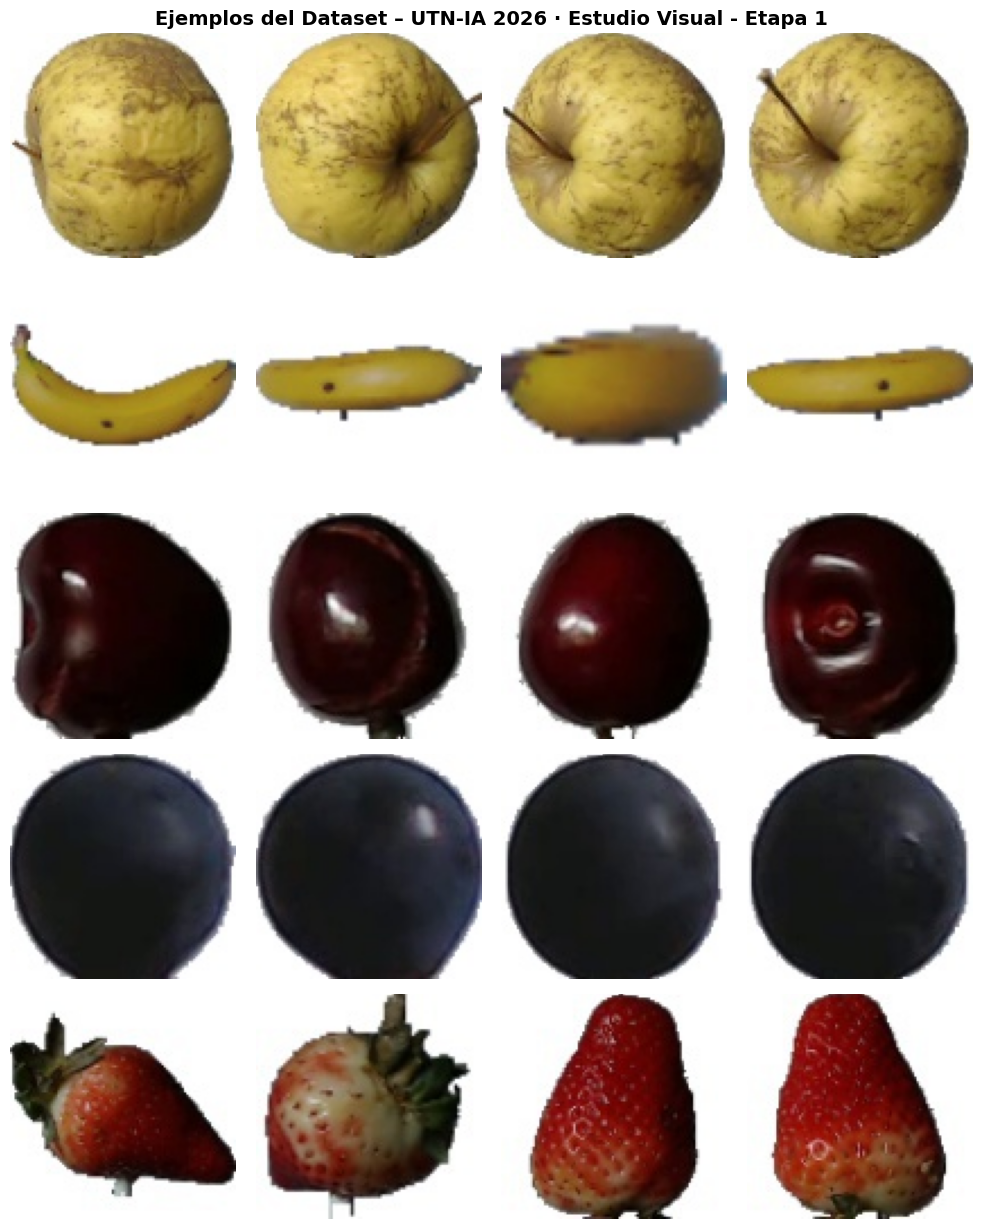

In [ ]:
def mostrar_ejemplos(base_dir, split='train', n=4):
    clases = sorted(os.listdir(base_dir / split))
    fig, axes = plt.subplots(len(clases), n, figsize=(n*2.5, len(clases)*2.5))
    fig.suptitle('Ejemplos del Dataset – UTN-IA 2026 · Estudio Visual - Etapa 1', fontsize=14, fontweight='bold')
    for i, clase in enumerate(clases):
        imgs = list((base_dir / split / clase).glob('*.jpg'))[:n]
        for j, p in enumerate(imgs):
            axes[i][j].imshow(Image.open(p))
            axes[i][j].axis('off')
            if j == 0:
                axes[i][j].set_ylabel(clase.split()[0], fontsize=10, fontweight='bold')
    plt.tight_layout(); plt.show()

mostrar_ejemplos(BASE_DIR)


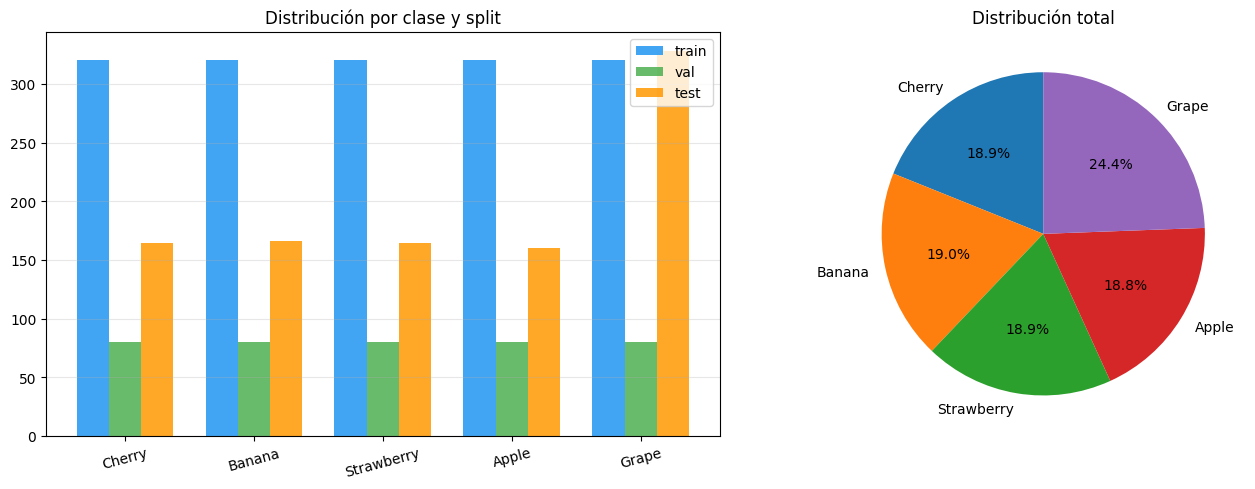

Clase                     Train      Val     Test
--------------------------------------------------
Cherry 1                    320       80      164
Banana 1                    320       80      166
Strawberry 1                320       80      164
Apple Golden 1              320       80      160
Grape Blue 1                320       80      328


In [ ]:
def analizar_distribucion(base_dir):
    splits = ['train', 'val', 'test']
    conteos = {s: {} for s in splits}
    for s in splits:
        sd = base_dir / s
        if sd.exists():
            for c in os.listdir(sd):
                conteos[s][c] = len(list((sd/c).glob('*.jpg')))

    clases = list(conteos['train'].keys())
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    x = np.arange(len(clases)); w = 0.25
    for idx, (s, col) in enumerate(zip(splits, ['#2196F3','#4CAF50','#FF9800'])):
        ax1.bar(x + idx*w, [conteos[s].get(c,0) for c in clases], w, label=s, color=col, alpha=0.85)
    ax1.set_xticks(x+w); ax1.set_xticklabels([c.split()[0] for c in clases], rotation=15)
    ax1.set_title('Distribución por clase y split'); ax1.legend(); ax1.grid(axis='y', alpha=0.3)

    totales = {c: sum(conteos[s].get(c,0) for s in splits) for c in clases}
    ax2.pie(totales.values(), labels=[c.split()[0] for c in clases], autopct='%1.1f%%', startangle=90)
    ax2.set_title('Distribución total')
    plt.tight_layout(); plt.show()

    print(f'{"Clase":<22} {"Train":>8} {"Val":>8} {"Test":>8}')
    print('-'*50)
    for c in clases:
        print(f'{c:<22} {conteos["train"].get(c,0):>8} {conteos["val"].get(c,0):>8} {conteos["test"].get(c,0):>8}')

analizar_distribucion(BASE_DIR)


### Paso 1.3: Preprocesamiento y Data Augmentation

Las CNNs esperan tensores normalizados. Definimos dos pipelines:
- **transform_base**: solo lo esencial (resize, tensor, normalize) → para val/test
- **transform_train**: agrega variaciones aleatorias → solo para entrenamiento

Los valores `mean=[0.485, 0.456, 0.406]` y `std=[0.229, 0.224, 0.225]` son los de ImageNet. Son los parámetros de normalización por canal RGB, calculados originalmente sobre el dataset ImageNet (1.2 millones de imágenes).

**Data Augmentation:**

Aplica solo al training set, nunca a val ni test. El objetivo es que en cada epoch el modelo vea versiones ligeramente distintas de la misma imagen, lo que actúa como regularización — el modelo no puede memorizar las imágenes de entrenamiento porque cada vez son un poco diferentes.
El efecto es equivalente a tener más datos sin recolectar nada nuevo.

In [ ]:
IMG_SIZE   = 64
BATCH_SIZE = 32
NUM_CLASES = 5
# Ponemos estos valores para no calcularlos
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

# Pipeline base: val y test
transform_base = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

# Pipeline con augmentation: solo training
transform_train = transforms.Compose([
    transforms.Resize((IMG_SIZE + 8, IMG_SIZE + 8)),   # → 72×72
    transforms.RandomCrop(IMG_SIZE),                   # → recorta 64×64 al azar
    transforms.RandomHorizontalFlip(p=0.5),            # → espejo horizontal, 50% de chances
    transforms.RandomRotation(degrees=15),             # → rota entre -15° y +15°
    transforms.ColorJitter(brightness=0.3,             # → varía brillo
                          contrast=0.3,                # → varía contraste
                          saturation=0.2,              # → varía saturación
                          hue=0.1),                    # → varía tono de color
    transforms.ToTensor(),                             # → Convierte a tensor
    transforms.Normalize(mean=MEAN, std=STD)           # → Normaliza
])

print('✅ Transformaciones definidas')
print('   Train: resize+crop+flip+rotación+colorjitter+normalize')
print('   Val/Test: solo resize+normalize')


✅ Transformaciones definidas
   Train: resize+crop+flip+rotación+colorjitter+normalize
   Val/Test: solo resize+normalize


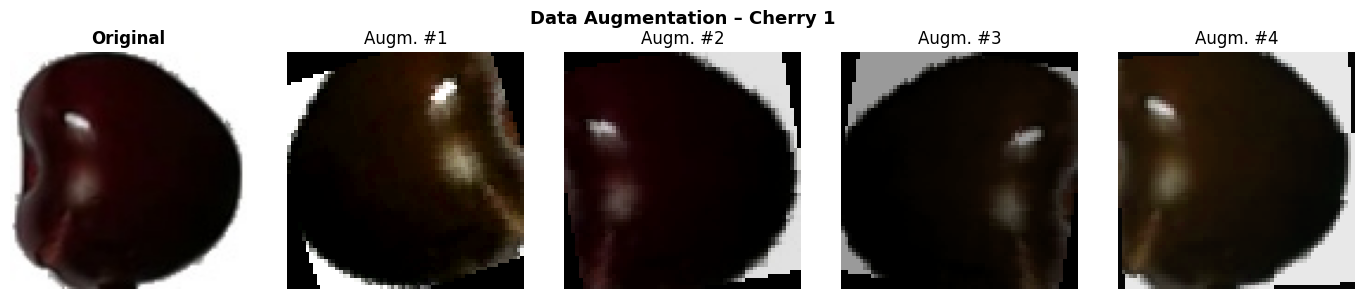

In [ ]:
def visualizar_augmentation(base_dir, clase, n=4):
    """Muestra la misma imagen con distintas augmentaciones."""
    carpeta = base_dir / 'train' / clase
    img_orig = Image.open(list(carpeta.glob('*.jpg'))[0])
    aug = transforms.Compose([
        transforms.Resize((IMG_SIZE+8, IMG_SIZE+8)),
        transforms.RandomCrop(IMG_SIZE),
        transforms.RandomHorizontalFlip(0.5),
        transforms.RandomRotation(20),
        transforms.ColorJitter(0.4, 0.4, 0.3, 0.1),
    ])
    fig, axes = plt.subplots(1, n+1, figsize=(14, 3))
    axes[0].imshow(img_orig); axes[0].set_title('Original', fontweight='bold'); axes[0].axis('off')
    for i in range(n):
        axes[i+1].imshow(aug(img_orig)); axes[i+1].set_title(f'Augm. #{i+1}'); axes[i+1].axis('off')
    plt.suptitle(f'Data Augmentation – {clase}', fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()

visualizar_augmentation(BASE_DIR, CLASES_SELECCIONADAS[-1])


In [ ]:
# Cargar datasets con ImageFolder (espera estructura: raiz/clase/imagen.jpg)
train_dataset = ImageFolder(str(BASE_DIR / 'train'), transform=transform_train)
val_dataset   = ImageFolder(str(BASE_DIR / 'val'),   transform=transform_base)
test_dataset  = ImageFolder(str(BASE_DIR / 'test'),  transform=transform_base)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

class_names = train_dataset.classes
print(f'✅ Datasets cargados: train={len(train_dataset)} | val={len(val_dataset)} | test={len(test_dataset)}')
print(f'   Clases: {class_names}')
imgs, labels = next(iter(train_loader))
print(f'   Forma del batch: {imgs.shape}  → [batch, canales, H, W]')


✅ Datasets cargados: train=1600 | val=400 | test=982
   Clases: ['Apple Golden 1', 'Banana 1', 'Cherry 1', 'Grape Blue 1', 'Strawberry 1']
   Forma del batch: torch.Size([32, 3, 64, 64])  → [batch, canales, H, W]


### Paso 1.4: Arquitectura de la CNN

```
Entrada (3×64×64)
    ↓ Conv1 (32 filtros 3×3) + BatchNorm + ReLU + MaxPool → 32×32×32
    ↓ Conv2 (64 filtros 3×3) + BatchNorm + ReLU + MaxPool → 64×16×16
    ↓ Conv3 (128 filtros 3×3) + BatchNorm + ReLU + MaxPool → 128×8×8
    ↓ Flatten → 8192
    ↓ Linear(8192, 256) + ReLU + Dropout(0.5)
    ↓ Linear(256, 5) → predicción
```

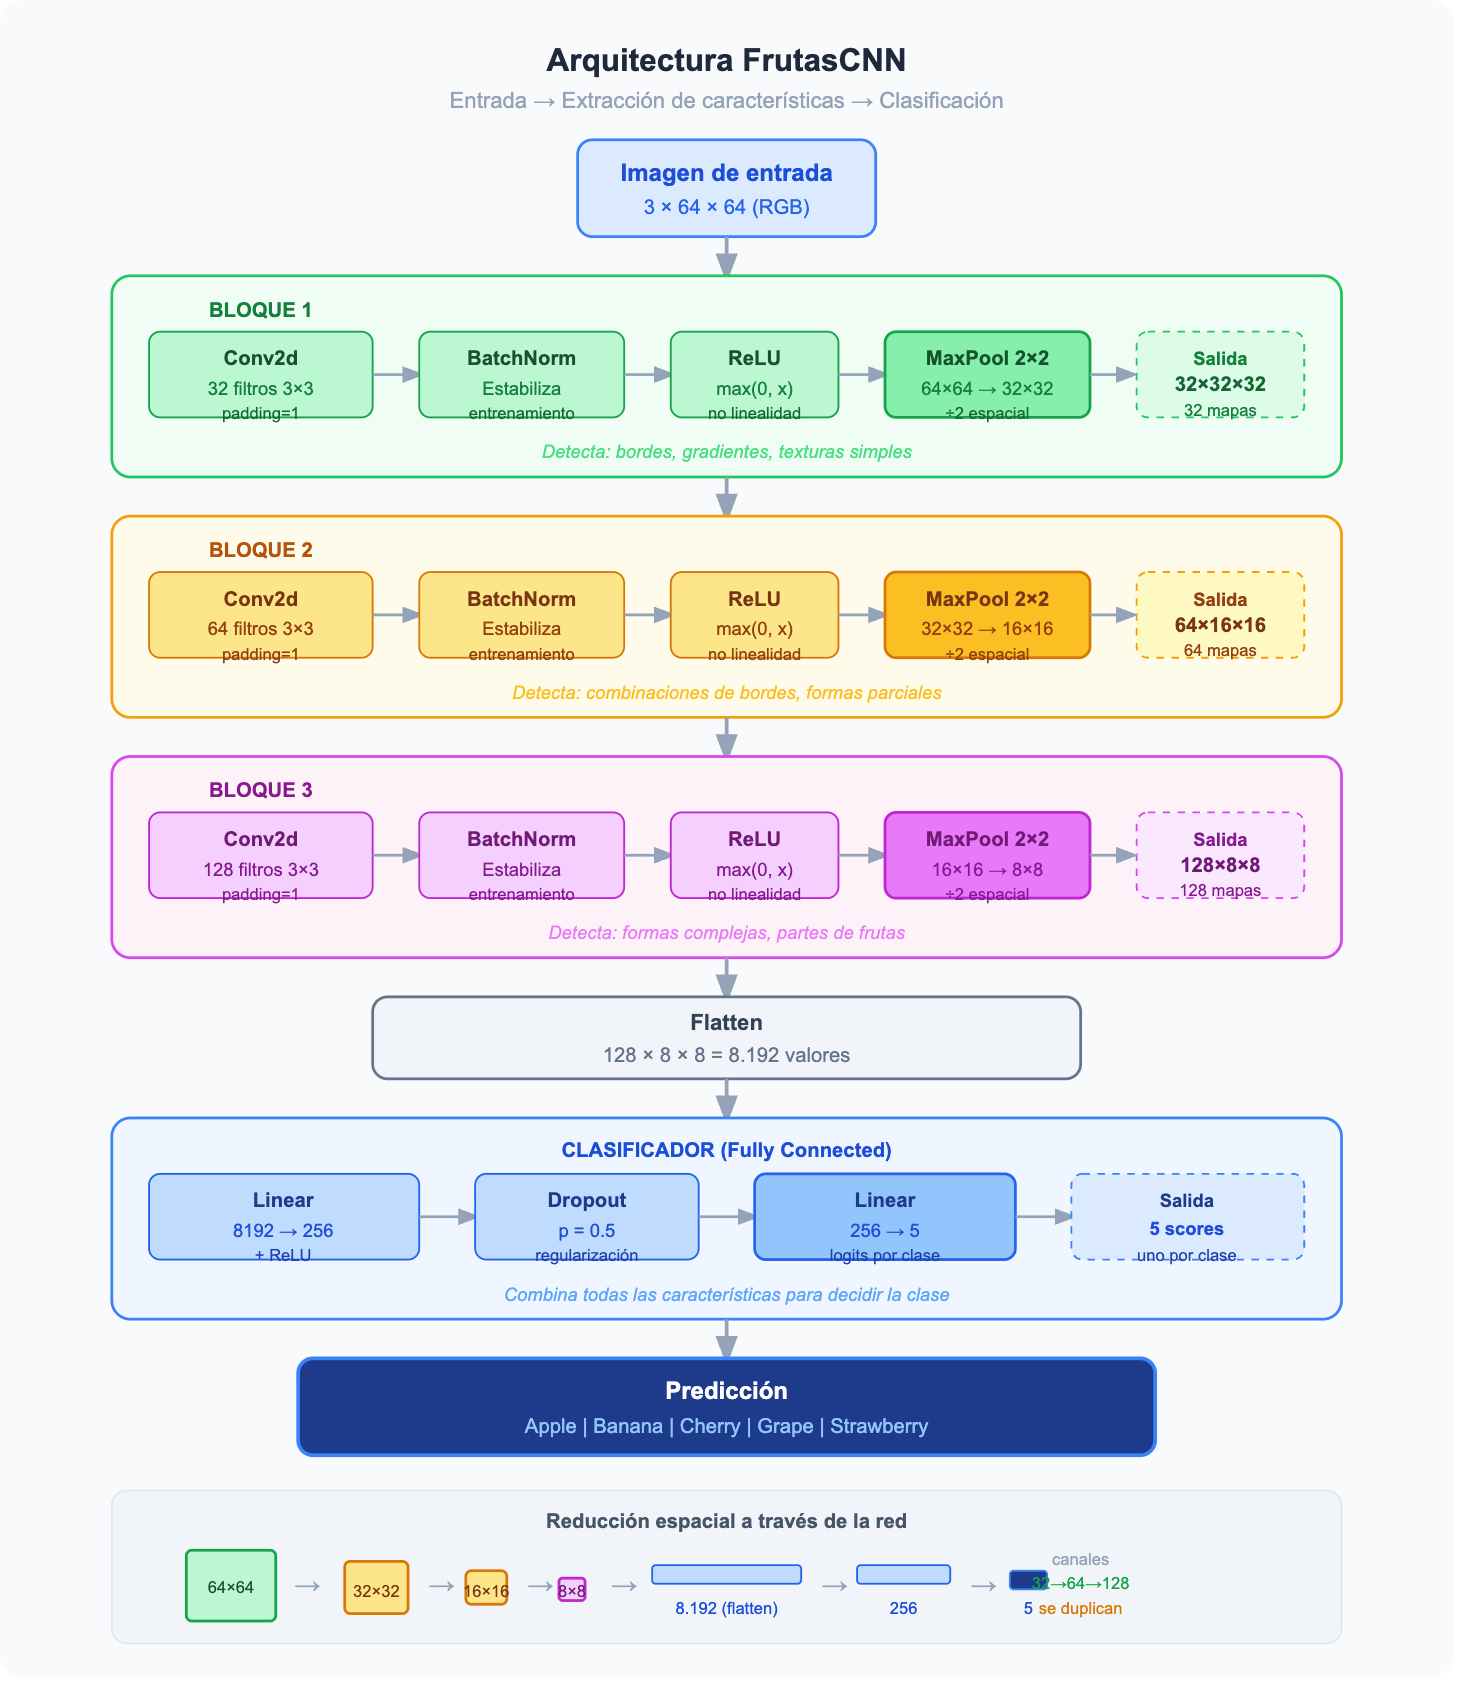


In [ ]:
class FrutasCNN(nn.Module):
    """
    CNN para clasificación de frutas.
    Cada bloque duplica filtros (32->64->128) y reduce tamaño espacial con MaxPool.
    """
    def __init__(self, num_classes=5):
        super().__init__()
        # Bloque 1: detecta bordes y texturas simples
        self.bloque1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),  # 3 canales RGB -> 32 mapas
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)   # 64x64 -> 32x32
        )
        # Bloque 2: detecta combinaciones de bordes
        self.bloque2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)   # 32x32 -> 16x16
        )
        # Bloque 3: detecta representaciones complejas
        self.bloque3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)   # 16x16 -> 8x8
        )
        # Clasificador final
        self.clasificador = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(p=0.5),   # Regularización contra overfitting
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.bloque1(x)
        x = self.bloque2(x)
        x = self.bloque3(x)
        return self.clasificador(x)

modelo = FrutasCNN(num_classes=NUM_CLASES).to(device)
total_params = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
print(f'✅ Modelo creado | Parámetros entrenables: {total_params:,}')
print(modelo)


✅ Modelo creado | Parámetros entrenables: 2,192,389
FrutasCNN(
  (bloque1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (bloque2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (bloque3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (clasificador): Sequential(
    (0): Flatten(start_dim=

**Test rápido:**
Crea una imagen falsa y la pasa por el modelo para verificar que las dimensiones son correctas antes de entrenar con datos reales.

`torch.randn(4, 3, IMG_SIZE, IMG_SIZE)` genera números aleatorios con la misma forma que un batch real — 4 imágenes, 3 canales RGB, 64×64 píxeles. El contenido no importa, solo la forma.

Luego pasa ese tensor por el modelo y verifica que la salida tenga la forma correcta: [4, 5] — 4 imágenes, 5 scores (uno por fruta).

In [ ]:
# Test rápido de dimensiones
with torch.no_grad():
    x = torch.randn(4, 3, IMG_SIZE, IMG_SIZE).to(device)
    y = modelo(x)
    print(f'✅ Test de dimensiones:')
    print(f'   Entrada:  {x.shape}')
    print(f'   Salida:   {y.shape}  → 1 score por clase')


✅ Test de dimensiones:
   Entrada:  torch.Size([4, 3, 64, 64])
   Salida:   torch.Size([4, 5])  → 1 score por clase


### Paso 1.5: Entrenamiento

El ciclo de entrenamiento por cada batch:
1. **Forward pass**: el modelo hace predicciones
2. **Loss**: medimos el error con CrossEntropyLoss
3. **Backward pass**: calculamos gradientes
4. **Update**: el optimizador ajusta los pesos


In [ ]:
EPOCHS = 20
LR     = 1e-3

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(modelo.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)

def entrenar_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correcto, total = 0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        out = model(imgs)
        loss = criterion(out, labels)
        loss.backward()
        optimizer.step()
        _, preds = out.max(1)
        total_loss += loss.item() * imgs.size(0)
        correcto   += preds.eq(labels).sum().item()
        total      += imgs.size(0)
    return total_loss / total, correcto / total

@torch.no_grad()
def evaluar(model, loader, criterion, device):
    model.eval()
    total_loss, correcto, total = 0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        out = model(imgs)
        loss = criterion(out, labels)
        _, preds = out.max(1)
        total_loss += loss.item() * imgs.size(0)
        correcto   += preds.eq(labels).sum().item()
        total      += imgs.size(0)
    return total_loss / total, correcto / total

# Bucle principal
historial = {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[]}
mejor_val_loss = float('inf')
CKPT_PATH = '/content/mejor_modelo.pth'

print(f'{"Epoch":>6} | {"Train Loss":>10} | {"Train Acc":>10} | {"Val Loss":>10} | {"Val Acc":>10}')
print('-' * 58)

for epoch in range(1, EPOCHS + 1):
    tl, ta = entrenar_epoch(modelo, train_loader, criterion, optimizer, device)
    vl, va = evaluar(modelo, val_loader, criterion, device)
    scheduler.step(vl)
    for k, v in [('train_loss',tl),('val_loss',vl),('train_acc',ta),('val_acc',va)]:
        historial[k].append(v)
    marca = ''
    if vl < mejor_val_loss:
        mejor_val_loss = vl
        torch.save({'epoch':epoch, 'model_state_dict':modelo.state_dict(),
                    'val_acc':va, 'class_names':class_names}, CKPT_PATH)
        marca = ' ✅'
    print(f'{epoch:>6} | {tl:>10.4f} | {ta:>9.1%} | {vl:>10.4f} | {va:>9.1%}{marca}')


 Epoch | Train Loss |  Train Acc |   Val Loss |    Val Acc
----------------------------------------------------------
     1 |     0.4014 |     87.4% |     2.1026 |     77.2% ✅
     2 |     0.1093 |     97.1% |     0.0027 |    100.0% ✅
     3 |     0.0438 |     98.8% |     0.2542 |     91.5%
     4 |     0.0387 |     98.8% |     0.0232 |     99.0%
     5 |     0.0359 |     98.5% |     0.0202 |     99.0%
     6 |     0.0502 |     98.5% |     0.0002 |    100.0% ✅
     7 |     0.0233 |     99.3% |     0.0524 |     97.5%
     8 |     0.0427 |     98.7% |     0.0075 |    100.0%
     9 |     0.0217 |     99.4% |     0.0088 |    100.0%
    10 |     0.0235 |     99.4% |     0.0055 |    100.0%
    11 |     0.0097 |     99.8% |     0.0000 |    100.0% ✅
    12 |     0.0514 |     98.2% |     0.0631 |     97.0%
    13 |     0.0848 |     97.8% |     0.0096 |     99.8%
    14 |     0.0336 |     98.8% |     0.0105 |     99.5%
    15 |     0.0411 |     99.1% |     0.0000 |    100.0% ✅
    16 |     0.00

### Paso 1.6: Curvas de aprendizaje y evaluación

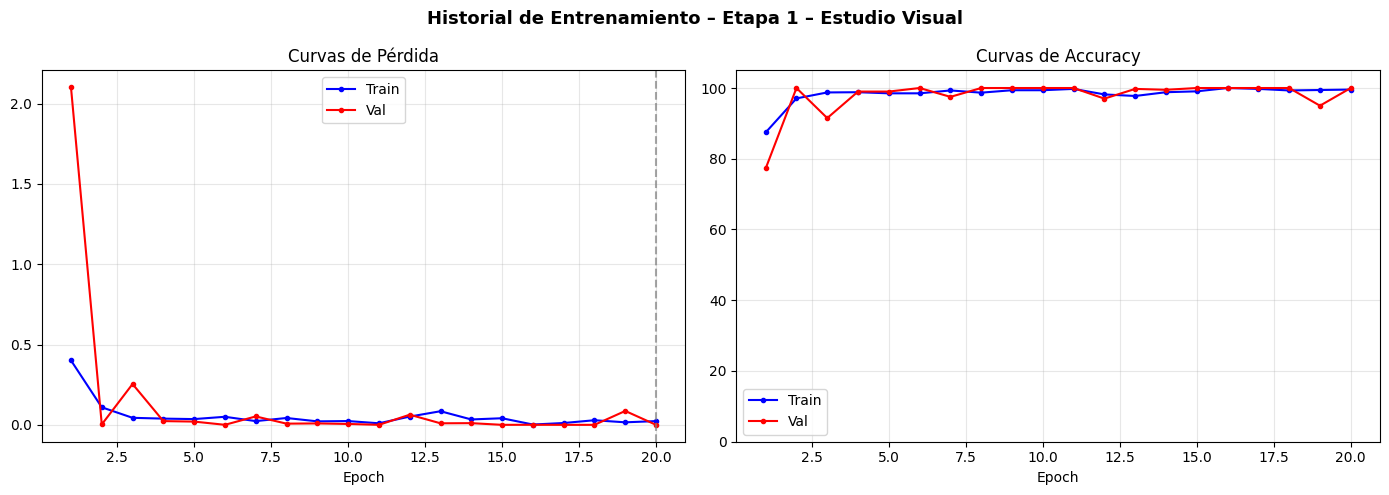

Mejor Val Accuracy: 100.00% (epoch 2)


In [ ]:
def graficar_historial(hist, titulo='Etapa 1 – Estudio Visual'):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ep = range(1, len(hist['train_loss'])+1)
    ax1.plot(ep, hist['train_loss'], 'b-o', ms=3, label='Train')
    ax1.plot(ep, hist['val_loss'],   'r-o', ms=3, label='Val')
    ax1.axvline(x=np.argmin(hist['val_loss'])+1, color='gray', ls='--', alpha=0.7)
    ax1.set_title('Curvas de Pérdida'); ax1.set_xlabel('Epoch'); ax1.legend(); ax1.grid(alpha=0.3)
    ax2.plot(ep, [a*100 for a in hist['train_acc']], 'b-o', ms=3, label='Train')
    ax2.plot(ep, [a*100 for a in hist['val_acc']],   'r-o', ms=3, label='Val')
    ax2.set_title('Curvas de Accuracy'); ax2.set_xlabel('Epoch'); ax2.set_ylim([0,105])
    ax2.legend(); ax2.grid(alpha=0.3)
    plt.suptitle(f'Historial de Entrenamiento – {titulo}', fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()
    print(f'Mejor Val Accuracy: {max(hist["val_acc"])*100:.2f}% (epoch {np.argmax(hist["val_acc"])+1})')

graficar_historial(historial)


In [ ]:
@torch.no_grad()
def obtener_predicciones(model, loader, device):
    model.eval()
    preds_all, labels_all = [], []
    for imgs, labels in loader:
        out = model(imgs.to(device))
        _, preds = out.max(1)
        preds_all.extend(preds.cpu().numpy())
        labels_all.extend(labels.numpy())
    return np.array(preds_all), np.array(labels_all)

# Cargar mejor modelo
ckpt = torch.load(CKPT_PATH, map_location=device)
modelo.load_state_dict(ckpt['model_state_dict'])
print(f'✅ Mejor modelo cargado (epoch {ckpt["epoch"]}, val_acc={ckpt["val_acc"]:.2%})')

preds, labels_reales = obtener_predicciones(modelo, test_loader, device)
print(f'\nTest Accuracy: {(preds==labels_reales).mean():.2%}\n')
print(classification_report(labels_reales, preds, target_names=[c.split()[0] for c in class_names]))


✅ Mejor modelo cargado (epoch 20, val_acc=100.00%)

Test Accuracy: 89.21%

              precision    recall  f1-score   support

       Apple       1.00      1.00      1.00       160
      Banana       1.00      1.00      1.00       166
      Cherry       1.00      1.00      1.00       164
       Grape       1.00      0.68      0.81       328
  Strawberry       0.61      1.00      0.76       164

    accuracy                           0.89       982
   macro avg       0.92      0.94      0.91       982
weighted avg       0.93      0.89      0.89       982



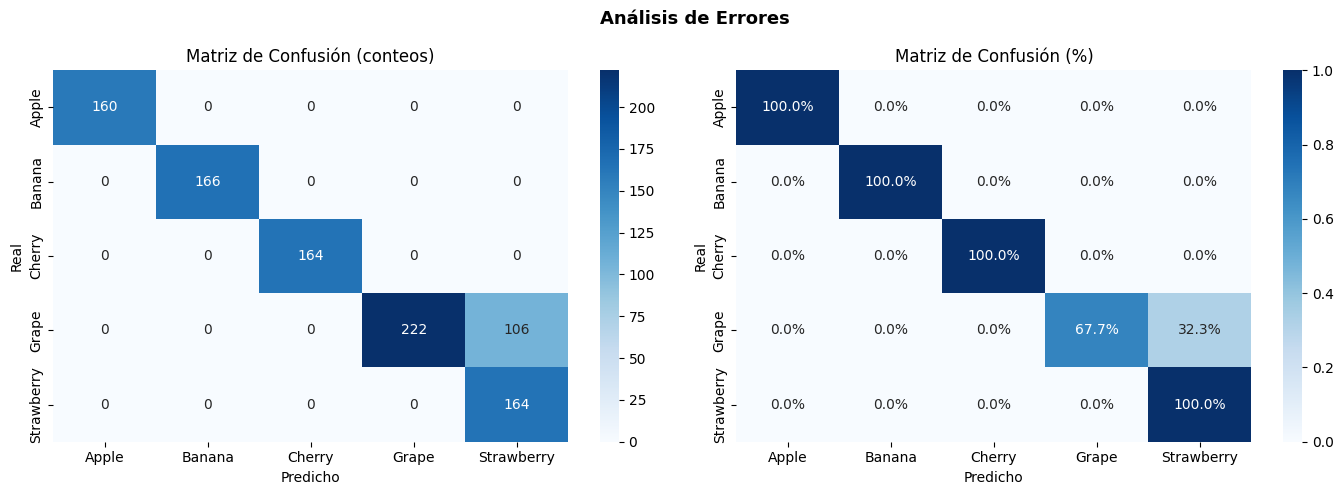

In [ ]:
def graficar_confusion(preds, labels, class_names):
    nombres = [c.split()[0] for c in class_names]
    cm = confusion_matrix(labels, preds)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, None]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    sns.heatmap(cm,      annot=True, fmt='d',    cmap='Blues', xticklabels=nombres, yticklabels=nombres, ax=ax1)
    sns.heatmap(cm_norm, annot=True, fmt='.1%',  cmap='Blues', xticklabels=nombres, yticklabels=nombres, ax=ax2)
    ax1.set_title('Matriz de Confusión (conteos)');   ax1.set_ylabel('Real'); ax1.set_xlabel('Predicho')
    ax2.set_title('Matriz de Confusión (%)');        ax2.set_ylabel('Real'); ax2.set_xlabel('Predicho')
    plt.suptitle('Análisis de Errores', fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()

graficar_confusion(preds, labels_reales, class_names)


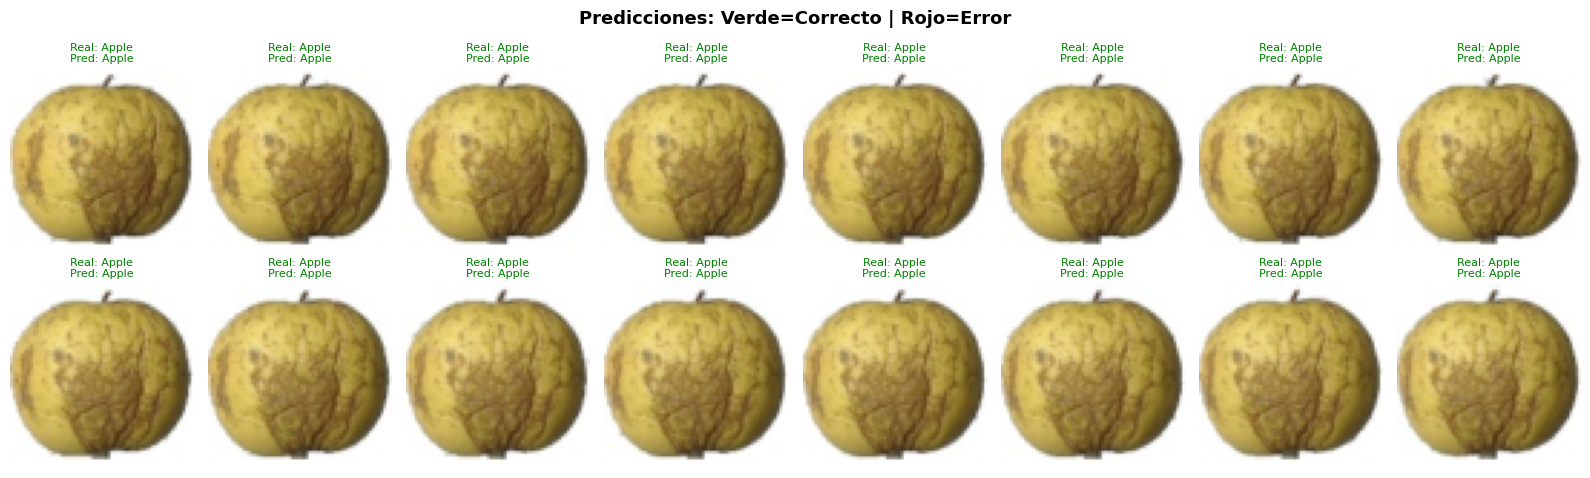

In [ ]:
def visualizar_predicciones(model, loader, class_names, device, n=16):
    """Muestra predicciones: verde=correcto, rojo=error."""
    model.eval()
    imgs_b, labels_b = next(iter(loader))
    with torch.no_grad():
        _, preds = model(imgs_b.to(device)).max(1)
    mean = torch.tensor(MEAN).view(3,1,1); std = torch.tensor(STD).view(3,1,1)
    imgs_d = (imgs_b * std + mean).clamp(0, 1)
    nombres = [c.split()[0] for c in class_names]
    cols = 8; rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*2, rows*2.5))
    axes = axes.flatten()
    for i in range(min(n, len(imgs_d))):
        img = imgs_d[i].permute(1,2,0).numpy()
        real  = nombres[labels_b[i]]
        pred  = nombres[preds[i].cpu()]
        ok = (labels_b[i] == preds[i].cpu())
        axes[i].imshow(img)
        axes[i].set_title(f'Real: {real}\nPred: {pred}', fontsize=8, color='green' if ok else 'red', fontweight='bold' if not ok else 'normal')
        axes[i].axis('off')
    for j in range(i+1, len(axes)): axes[j].axis('off')
    plt.suptitle('Predicciones: Verde=Correcto | Rojo=Error', fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()

visualizar_predicciones(modelo, test_loader, class_names, device)


---
#  ETAPA 2: Dataset UTN-IA 2026
## El desafío de generalización

Usamos el mismo modelo con un dataset con fondos variables e iluminación real.
El modelo obtendrá **peor desempeño**. Esta es la lección más importante:

> **El dataset determina tanto o más que la arquitectura.**

**Dataset:** UTN-IA 2026 · Food Classification - Training Set  
**Link:** https://www.kaggle.com/datasets/geronimoforconi/utn-ia-2026-food-classification-training-set  
**Licencia:** Apache 2.0

> ⚠️ Este es el **dataset oficial de la competencia**. Las imágenes de test tienen fondos variados — el mismo modelo que obtuvo ~95% en Etapa 1 verá aquí cómo la distribución del dataset impacta el rendimiento real.


In [ ]:
!kaggle datasets download -d geronimoforconi/utn-ia-2026-food-classification-training-set \
    -p /content/data/fruit_recognition --unzip -q
print("✅ Dataset UTN-IA 2026 descargado")

raiz_r = Path("/content/data/fruit_recognition")


Dataset URL: https://www.kaggle.com/datasets/geronimoforconi/utn-ia-2026-food-classification-training-set
License(s): apache-2.0
✅ Dataset UTN-IA 2026 descargado


## Etapa 2: UTN-IA 2026 · Food Classification - Training Set

In [ ]:
# ============================================================
# Etapa 2: UTN-IA 2026 · Food Classification - Training Set
# El dataset tiene solo imágenes de train → dividimos en train/val/test
# ============================================================
import shutil, random
from pathlib import Path

RAIZ_FOOD = Path('/content/data/fruit_recognition')
BASE_DIR_R = Path('/content/data/fruit_recognition_splint/')
CLASES_R   = ['apple', 'banana', 'grapes', 'potato', 'tomato']

# Proporciones del split (deben sumar 1.0)
SPLIT_TRAIN = 0.70
SPLIT_VAL   = 0.15
SPLIT_TEST  = 0.15

def crear_subset_desde_train(clases, raiz, destino, split_train=0.70, split_val=0.15):
    """
    Busca imágenes bajo raiz/<clase>/ o raiz/train/<clase>/,
    hace split estratificado y copia a destino/train|val|test/<clase>/.
    """
    # Detectar si las clases están directamente o bajo una subcarpeta 'train/'
    probe = raiz / clases[0]
    src_base = raiz if probe.exists() else raiz / 'train'

    for clase in clases:
        imgs = sorted([
            p for p in (src_base / clase).glob('**/*')
            if p.suffix.lower() in ('.jpg', '.jpeg', '.png')
        ])
        if not imgs:
            print(f'⚠️  Sin imágenes para clase "{clase}" en {src_base}')
            continue

        random.shuffle(imgs)
        n = len(imgs)
        n_val  = int(n * split_val)
        n_test = int(n * (1 - split_train - split_val))

        splits = {
            'val':   imgs[:n_val],
            'test':  imgs[n_val:n_val + n_test],
            'train': imgs[n_val + n_test:],
        }

        for split_name, subset in splits.items():
            dst = destino / split_name / clase
            dst.mkdir(parents=True, exist_ok=True)
            for img in subset:
                shutil.copy(img, dst / img.name)

        print(f'  {clase}: {len(splits["train"])} train | {len(splits["val"])} val | {len(splits["test"])} test')

    print(f'\n✅ Split creado en {destino}')

crear_subset_desde_train(CLASES_R, RAIZ_FOOD, BASE_DIR_R, SPLIT_TRAIN, SPLIT_VAL)

  apple: 39 train | 7 val | 7 test
  banana: 42 train | 9 val | 9 test
  grapes: 56 train | 11 val | 11 test
  potato: 44 train | 9 val | 9 test
  tomato: 52 train | 10 val | 10 test

✅ Split creado en /content/data/fruit_recognition_splint


## Seleccionar mismas frutas que en Etapa 1 para comparación directa


✅ Subset realista creado


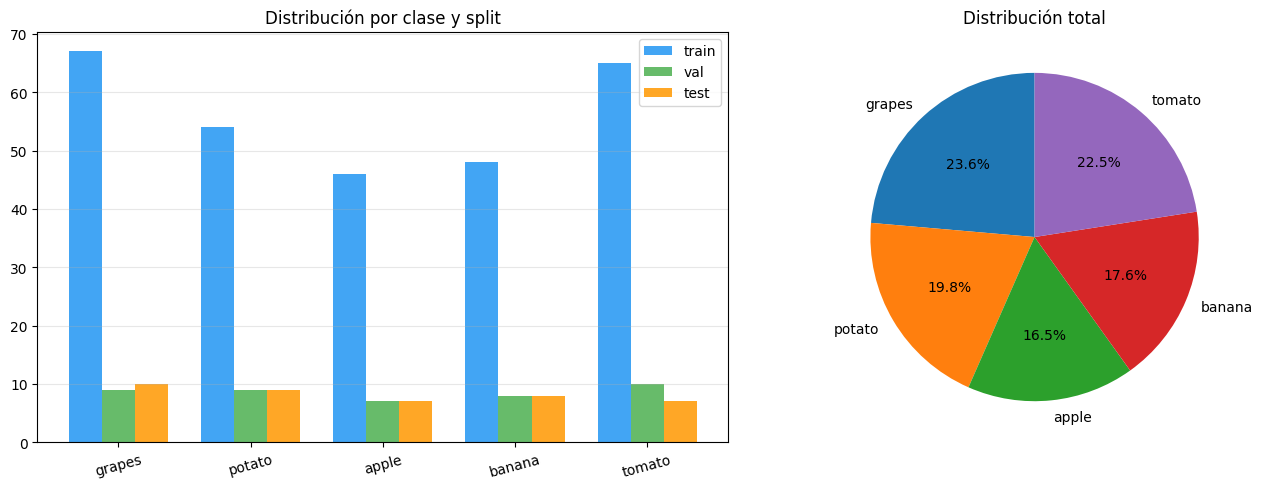

Clase                     Train      Val     Test
--------------------------------------------------
grapes                       67        9       10
potato                       54        9        9
apple                        46        7        7
banana                       48        8        8
tomato                       65       10        7


In [ ]:
for split, split_src_name in [('train','train'), ('val','validation'), ('test','test')]:
    src_base = raiz_r / split_src_name
    if not src_base.exists(): continue
    for clase in CLASES_R:
        src = src_base / clase
        if src.exists():
            dst = BASE_DIR_R / split / clase
            dst.mkdir(parents=True, exist_ok=True)
            for img in src.glob('*.*'):
                if img.suffix.lower() in ['.jpg','.jpeg','.png']:
                    shutil.copy(img, dst / img.name)

print('✅ Subset realista creado')
analizar_distribucion(BASE_DIR_R)


## Comparación visual: Etapa 1 (Estudio Visual) vs Etapa 2 (Training Set)


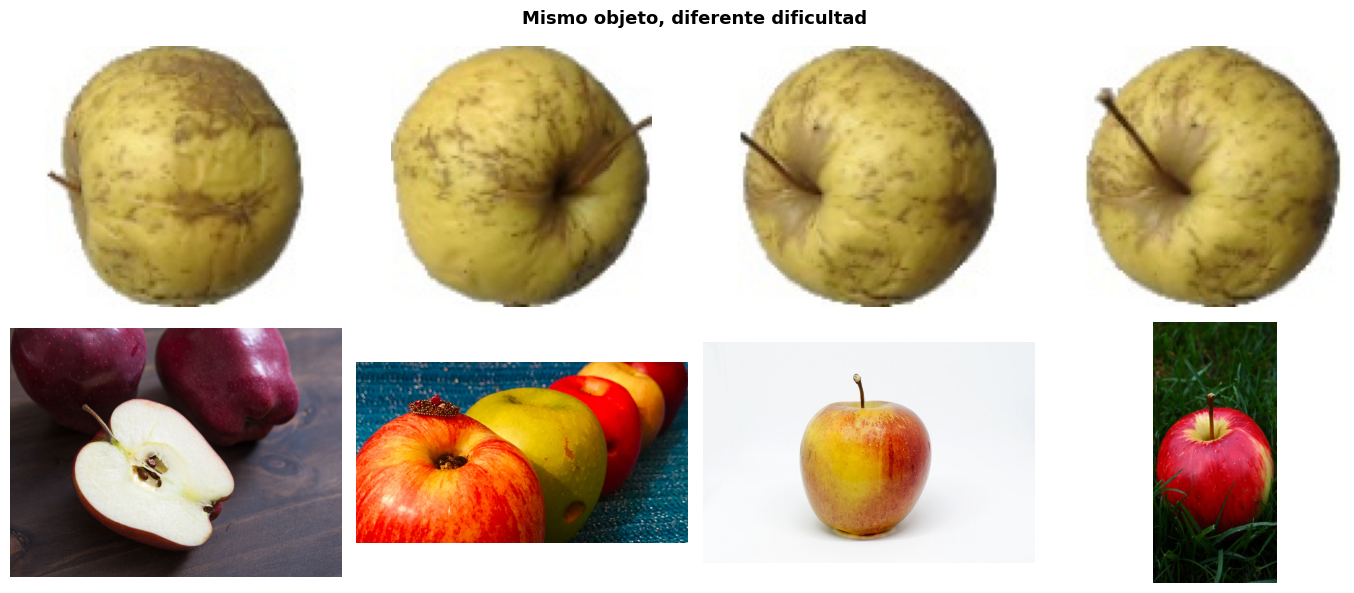

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for row, (base, clase, titulo) in enumerate([
    (BASE_DIR,   CLASES_SELECCIONADAS[0], 'UTN-IA 2026 · Estudio Visual - Etapa 1'),
    (BASE_DIR_R, CLASES_R[0],             'Dataset Realista')
]):
    carpeta = base / 'train' / clase
    imgs = list(carpeta.glob('*.jpg'))[:4] or list(carpeta.glob('*.png'))[:4]
    for col, img_path in enumerate(imgs[:4]):
        axes[row][col].imshow(Image.open(img_path))
        axes[row][col].axis('off')
        if col == 0: axes[row][col].set_ylabel(titulo, fontsize=10, fontweight='bold')
plt.suptitle('Mismo objeto, diferente dificultad', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()


## Augmentation

In [ ]:
# Augmentation más agresivo para el dataset realista (pocos datos, más variabilidad)
transform_train_r = transforms.Compose([
    transforms.Resize((IMG_SIZE+16, IMG_SIZE+16)),
    transforms.RandomCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomVerticalFlip(0.2),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.3, hue=0.1),
    transforms.RandomGrayscale(0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

#algunas imagenes estaban con formato transparente

from PIL import Image

def cargar_imagen_limpia(path):
    img = Image.open(path)
    # Convertir formatos problemáticos a RGB estándar
    if img.mode in ('P', 'RGBA', 'LA'):
        img = img.convert('RGBA')
        fondo = Image.new('RGB', img.size, (255, 255, 255))
        fondo.paste(img, mask=img.split()[3])  # usar canal alpha como máscara
        return fondo
    return img.convert('RGB')

train_r = ImageFolder(str(BASE_DIR_R/'train'), transform=transform_train_r,
                      loader=cargar_imagen_limpia)
val_r   = ImageFolder(str(BASE_DIR_R/'val'),   transform=transform_base,
                      loader=cargar_imagen_limpia)
test_r  = ImageFolder(str(BASE_DIR_R/'test'),  transform=transform_base,
                      loader=cargar_imagen_limpia)

train_loader_r = DataLoader(train_r, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader_r   = DataLoader(val_r,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader_r  = DataLoader(test_r,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

class_names_r = train_r.classes
print(f'✅ Dataset realista: train={len(train_r)} | val={len(val_r)} | test={len(test_r)}')


✅ Dataset realista: train=325 | val=46 | test=46


## Entrenar el MISMO modelo en el dataset realista


In [ ]:
modelo_r = FrutasCNN(num_classes=len(class_names_r)).to(device)
optimizer_r = optim.Adam(modelo_r.parameters(), lr=1e-3, weight_decay=1e-3)  # mayor regularización
scheduler_r = optim.lr_scheduler.ReduceLROnPlateau(optimizer_r, patience=5, factor=0.5)

historial_r = {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[]}
mejor_r = float('inf'); CKPT_R = '/content/mejor_modelo_realista.pth'

print(f'{"Epoch":>6} | {"Train Loss":>10} | {"Train Acc":>10} | {"Val Loss":>10} | {"Val Acc":>10}')
print('-'*58)

for epoch in range(1, EPOCHS+1):
    tl, ta = entrenar_epoch(modelo_r, train_loader_r, criterion, optimizer_r, device)
    vl, va = evaluar(modelo_r, val_loader_r, criterion, device)
    scheduler_r.step(vl)
    for k, v in [('train_loss',tl),('val_loss',vl),('train_acc',ta),('val_acc',va)]:
        historial_r[k].append(v)
    marca = ''
    if vl < mejor_r:
        mejor_r = vl
        torch.save({'epoch':epoch, 'model_state_dict':modelo_r.state_dict(), 'val_acc':va}, CKPT_R)
        marca = ' ✅'
    print(f'{epoch:>6} | {tl:>10.4f} | {ta:>9.1%} | {vl:>10.4f} | {va:>9.1%}{marca}')


 Epoch | Train Loss |  Train Acc |   Val Loss |    Val Acc
----------------------------------------------------------
     1 |     3.0818 |     25.5% |     1.8488 |     30.4% ✅
     2 |     1.8808 |     32.0% |     1.3792 |     47.8% ✅
     3 |     1.4221 |     43.4% |     1.2875 |     52.2% ✅
     4 |     1.3725 |     41.8% |     1.2315 |     47.8% ✅
     5 |     1.3284 |     44.3% |     1.1693 |     52.2% ✅
     6 |     1.3721 |     43.4% |     1.1874 |     54.3%
     7 |     1.3324 |     43.1% |     1.1613 |     54.3% ✅
     8 |     1.3385 |     39.1% |     1.1237 |     54.3% ✅
     9 |     1.3045 |     44.0% |     1.1749 |     60.9%
    10 |     1.3420 |     44.0% |     1.1504 |     56.5%
    11 |     1.2608 |     45.8% |     1.1097 |     58.7% ✅
    12 |     1.2791 |     46.2% |     1.0505 |     65.2% ✅
    13 |     1.2426 |     48.6% |     1.1460 |     63.0%
    14 |     1.2879 |     44.3% |     1.0856 |     60.9%
    15 |     1.2661 |     49.5% |     0.9705 |     76.1% ✅
    16 

# Comparación final: Dataset controlado vs. Realista

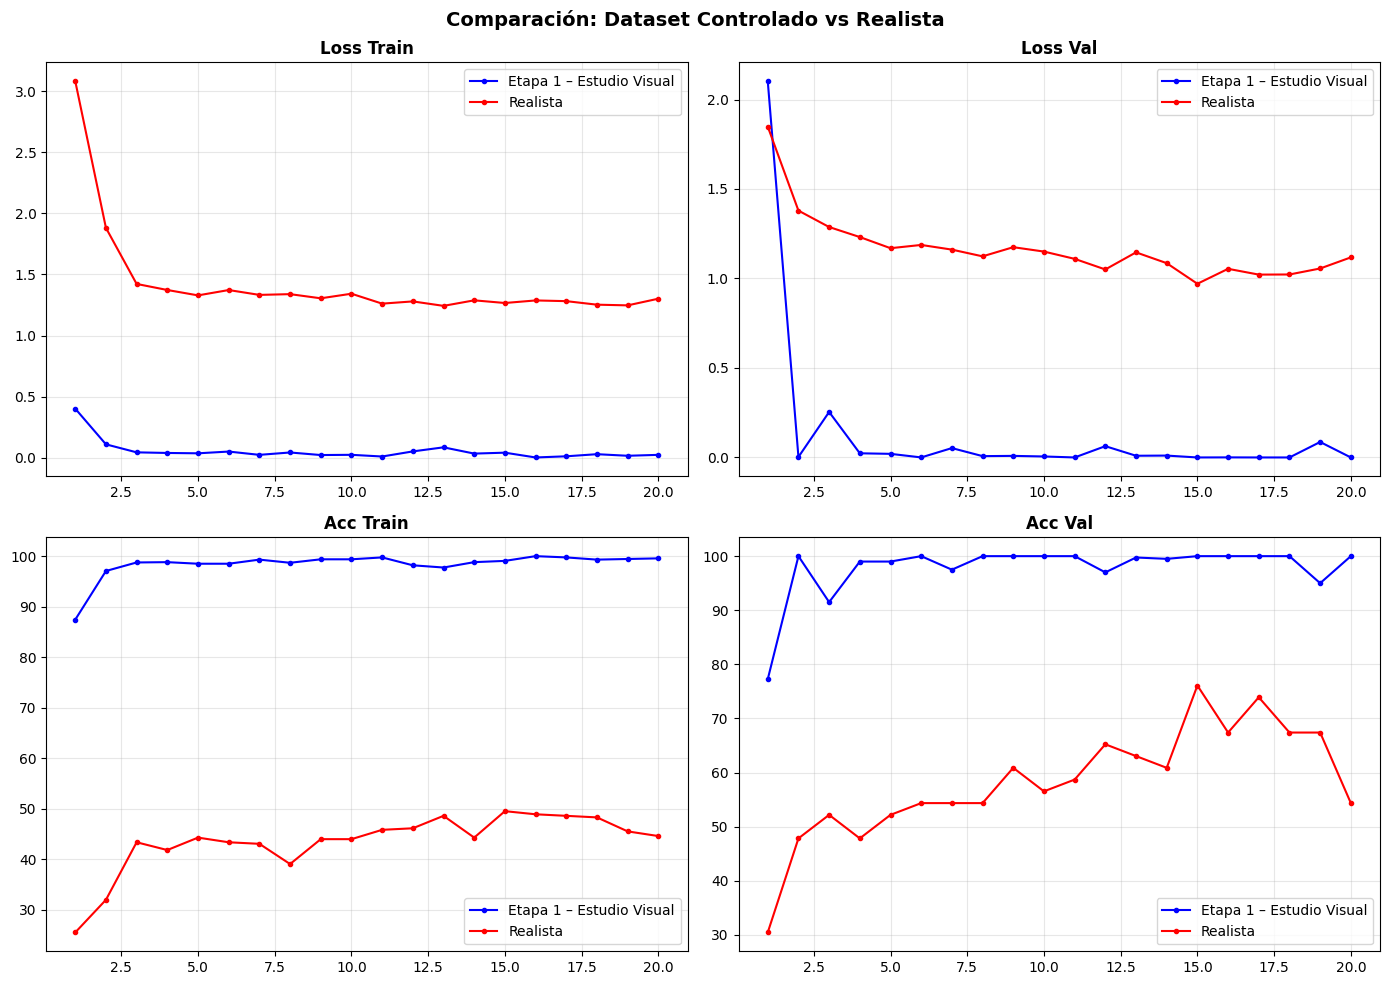

Dataset              Best Val Acc  Best Val Loss
------------------------------------------------
Etapa 1 – Estudio Visual      100.00%         0.0000
Realista                   76.09%         0.9705


In [ ]:
def comparar_resultados(h1, h2, label1='Etapa 1 – Estudio Visual', label2='Realista'):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    keys = [('train_loss','Loss Train'),('val_loss','Loss Val'),('train_acc','Acc Train'),('val_acc','Acc Val')]
    for ax, (key, titulo) in zip(axes.flatten(), keys):
        v1 = [x*100 for x in h1[key]] if 'acc' in key else h1[key]
        v2 = [x*100 for x in h2[key]] if 'acc' in key else h2[key]
        ax.plot(range(1,len(v1)+1), v1, 'b-o', ms=3, label=label1)
        ax.plot(range(1,len(v2)+1), v2, 'r-o', ms=3, label=label2)
        ax.set_title(titulo, fontweight='bold'); ax.legend(); ax.grid(alpha=0.3)
    plt.suptitle('Comparación: Dataset Controlado vs Realista', fontsize=14, fontweight='bold')
    plt.tight_layout(); plt.show()
    print(f'{"Dataset":<20} {"Best Val Acc":>12} {"Best Val Loss":>14}')
    print('-'*48)
    print(f'{label1:<20} {max(h1["val_acc"])*100:>11.2f}% {min(h1["val_loss"]):>14.4f}')
    print(f'{label2:<20} {max(h2["val_acc"])*100:>11.2f}% {min(h2["val_loss"]):>14.4f}')

comparar_resultados(historial, historial_r)


---
#  Submission para la Competencia Kaggle
## UTN-IA 2026: Fruit & Vegetable Classifier

Una vez entrenado el modelo en Etapa 2, generamos el archivo `submission.csv` para subirlo a la competencia.

**Competencia:** https://www.kaggle.com/competitions/utn-ia-2026-fruit-vegetable-classifier

**Formato requerido:**
```
image_id,label
img_0001.jpg,apple
img_0002.jpg,tomato
...
```

**Clases válidas:** `apple`, `banana`, `grapes`, `potato`, `tomato`


In [ ]:
# Descargar el zip en /content/data
!mkdir -p /content/data

!kaggle competitions download \
    -c utn-ia-2026-fruit-vegetable-classifier \
    -p /content/data

# Renombrar
!mv /content/data/utn-ia-2026-fruit-vegetable-classifier.zip \
    /content/data/utn_competencia_test.zip

# Crear carpeta destino
!mkdir -p /content/data/test_competencia

# Descomprimir
!unzip -q /content/data/utn_competencia_test.zip \
    -d /content/data/test_competencia

100% 38.9M/38.9M [00:00<00:00, 175MB/s]



In [ ]:
DIR_TEST = Path("/content/data/test_competencia/utn_competencia_test/test_images")
imagenes_test = sorted([p for p in DIR_TEST.rglob("*") if p.suffix.lower() in [".jpg",".jpeg",".png"]])
print(f"✅ {len(imagenes_test)} imágenes de test listas para predecir")


✅ 89 imágenes de test listas para predecir


In [ ]:
import pandas as pd

# Clases válidas en el mismo orden que el modelo fue entrenado
CLASES_COMP = ["apple", "banana", "grapes", "potato", "tomato"]

# Usar el modelo entrenado en Etapa 2 (modelo_r)
# Si querés usar el de Etapa 1, reemplazá modelo_r por modelo
modelo_submit = modelo_r
modelo_submit.eval()

predicciones = []

with torch.no_grad():
    for img_path in imagenes_test:
        img = Image.open(img_path).convert("RGB")
        tensor = transform_base(img).unsqueeze(0).to(device)
        logits = modelo_submit(tensor)
        pred_idx = logits.argmax(dim=1).item()
        pred_label = class_names_r[pred_idx]  # nombre de clase del modelo
        # Normalizar al nombre exacto de la competencia
        pred_label = pred_label.lower().strip()
        predicciones.append({
            "image_id": os.path.splitext(img_path.name)[0],
            "label": pred_label
        })

df_sub = pd.DataFrame(predicciones)
print(df_sub.head(10))
print(f"Distribución de predicciones:")
print(df_sub["label"].value_counts())


/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


    image_id   label
0  img_00000  grapes
1  img_00001  grapes
2  img_00002   apple
3  img_00003  banana
4  img_00004  tomato
5  img_00005  grapes
6  img_00006  banana
7  img_00007  banana
8  img_00008  grapes
9  img_00009  grapes
Distribución de predicciones:
label
grapes    38
tomato    28
banana    18
potato     3
apple      2
Name: count, dtype: int64


In [ ]:
# Validar que todas las clases predichas son válidas
clases_invalidas = df_sub[~df_sub["label"].isin(CLASES_COMP)]
if len(clases_invalidas) > 0:
    print(f"⚠️ {len(clases_invalidas)} predicciones con clases inválidas:")
    print(clases_invalidas)
else:
    print(f"✅ Todas las {len(df_sub)} predicciones tienen clases válidas")

# Guardar submission.csv
df_sub.to_csv("/content/submission.csv", index=False)
print("📄 submission.csv guardado")
print("  → Subilo en: https://www.kaggle.com/competitions/utn-ia-2026-fruit-vegetable-classifier/submit")


✅ Todas las 89 predicciones tienen clases válidas
📄 submission.csv guardado
  → Subilo en: https://www.kaggle.com/competitions/utn-ia-2026-fruit-vegetable-classifier/submit


---
## Conclusiones

1. **El dataset importa tanto como la arquitectura** — UTN-IA 2026 · Estudio Visual - Etapa 1 (aprox 95%) vs. dataset realista (aprox 75%) con el mismo modelo.
2. **Data Augmentation = regularización** — no solo aumenta datos, enseña robustez al modelo.
3. **Las métricas deben complementarse** — accuracy + F1 + matriz de confusión dan una imagen completa.

## 🎯 Trabajo Práctico: subir el puntaje en la competencia

Con el notebook de clase tenés un baseline. Para el TP, explorá:

- **Transfer Learning** — ResNet18, EfficientNet, ViT preentrenados en ImageNet
- **Data Augmentation agresivo** — MixUp, CutMix, RandAugment
- **Fine-tuning** — descongelar capas del backbone gradualmente
- **Ensemble** — promediar predicciones de varios modelos
- **Test-Time Augmentation (TTA)** — predecir con múltiples crops/flips y promediar

**Métrica:** F1 Score Weighted — penaliza clases minoritarias mal predichas.
**URL competencia:** https://www.kaggle.com/competitions/utn-ia-2026-fruit-vegetable-classifier


---
---

#  ETAPA 3: Transfer Learning con EfficientNet-B0

> **Experimento #1 del Trabajo Práctico.** Punto de partida: el baseline de la Etapa 2
> (CNN desde cero, 64×64) alcanzó ~76% de val accuracy y en el test de Kaggle colapsó hacia `grapes` (38 de 89 predicciones).

## Diagnóstico del baseline

Antes de tocar nada, conviene entender **por qué** el baseline falla. Hay cuatro problemas, y cada
uno tiene su contramedida en esta etapa:

| # | Problema detectado en Etapa 2 | Contramedida en Etapa 3 |
|---|-------------------------------|--------------------------|
| 1 | **Muy pocos datos** (~420 imágenes en total). Una CNN desde cero necesita decenas de miles. | **Transfer learning**: EfficientNet-B0 llega con features aprendidas de 1.28M imágenes de ImageNet (que además ya incluye manzanas, bananas y limones). Solo hay que *adaptar*, no *aprender de cero*. |
| 2 | **Resolución 64×64**. A ese tamaño se pierde la textura (piel de la papa vs. piel del tomate) y quedan casi solo color y silueta. | **224×224**, la resolución nativa con la que EfficientNet-B0 fue preentrenada. |
| 3 | **Domain gap**: el train tiene **fondo blanco de estudio**, el test de Kaggle tiene **fondos variados**. El modelo aprende "fondo blanco + rojo = tomate" y en el test se rompe. | **Augmentation agresivo orientado al fondo**: `RandomResizedCrop` (fuerza a mirar el objeto, no la escena), `RandAugment`, `RandomErasing` y recomposición de fondos aleatorios en imágenes con canal alpha. |
| 4 | **El checkpoint se elegía por `val_loss`**, pero la competencia mide **F1 Score Weighted**. | El checkpoint ahora se guarda por **mejor F1 weighted en validación**. Optimizo lo que evalúa la competencia. |

## Experimento 1

| Ítem | Valor |
|------|-------|
| **Arquitectura** | EfficientNet-B0 (ImageNet IMAGENET1K_V1) |
| **Resolución** | 224×224 |
| **Estrategia** | 2 fases: feature extraction (6 ep) → fine-tuning con LR discriminativos (30 ep) |
| **Augmentation** | RandomResizedCrop(0.4–1.0) + flips + RandAugment(2,9) + RandomErasing + fondo aleatorio |
| **Loss** | CrossEntropy + label smoothing 0.1 |
| **Optimizador** | AdamW (backbone 3e-5 / head 3e-4) + CosineAnnealingLR |
| **Selección de checkpoint** | Mejor **F1 weighted** en validación |
| **Inferencia** | TTA ×3 (original + hflip + vflip) |

## Estrategia de entrenamiento: 2 fases

Descongelar todo el backbone desde el epoch 1 con pocos datos **destruye** los pesos preentrenados
(los gradientes enormes del clasificador random se propagan hacia atrás). Por eso:

- **Fase A — Feature Extraction (backbone congelado):** solo entreno el clasificador nuevo.
  El backbone actúa como extractor de features fijo. Rápido y estabiliza el head.
- **Fase B — Fine-tuning (backbone descongelado):** ya con el head "calibrado", descongelo
  todo y entreno con **learning rates discriminativos** (LR bajo para el backbone, LR alto
  para el head) + `CosineAnnealingLR`.

## ⚠️ Advertencia metodológica importante

Nuestro set de validación local sale del **mismo dataset de fondo blanco** que el train.
Por lo tanto **la validación local va a ser optimista** (probablemente 95-100%) y **no** predice
bien el score de Kaggle. Es una métrica útil para detectar bugs y overfitting groseros, pero
**el único juez real es el leaderboard**. Lo dejo explícito y más abajo agrego un
"val_hard" (validación con fondos y crops perturbados) que es un proxy más honesto.


### Paso 3.0 — Configuración e hiperparámetros de la Etapa 3

Todos los hiperparámetros centralizados en un solo lugar: así cada experimento futuro se
documenta cambiando esta celda y anotando el resultado en la bitácora.


In [ ]:
# ============================================================
# ETAPA 3 · CONFIGURACIÓN
# ============================================================
import os, time, random, hashlib, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from pathlib import Path
from PIL import Image

# --- Datos ---
CLASES_TL   = ['apple', 'banana', 'grapes', 'potato', 'tomato']  # orden = índices del modelo
NUM_CLASES_TL = len(CLASES_TL)
VAL_SPLIT   = 0.15        # 15% para validación (el dataset es chico: no puedo regalar más)

# --- Imagen ---
IMG_SIZE_TL = 224         # resolución nativa de EfficientNet-B0 (vs. 64 del baseline)
MEAN = [0.485, 0.456, 0.406]   # estadísticas de ImageNet: OBLIGATORIAS al usar pesos preentrenados
STD  = [0.229, 0.224, 0.225]   # (el backbone espera exactamente esta normalización)

# --- Entrenamiento ---
BATCH_SIZE_TL = 32
EPOCHS_HEAD   = 6         # Fase A: backbone congelado
EPOCHS_FT     = 30        # Fase B: fine-tuning completo
LR_HEAD       = 1e-3      # LR del clasificador en Fase A
LR_FT_HEAD    = 3e-4      # LR del clasificador en Fase B
LR_FT_BACKBONE= 3e-5      # LR del backbone en Fase B (10x más chico: no quiero destruir ImageNet)
WEIGHT_DECAY  = 1e-4
LABEL_SMOOTH  = 0.1       # suaviza los targets: menos overconfianza, mejor generalización
DROPOUT_HEAD  = 0.4

CKPT_TL = '/content/mejor_efficientnet_b0.pth'

# Semillas (reproducibilidad = requisito para comparar experimentos honestamente)
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'✅ Config Etapa 3 lista | device={device} | img={IMG_SIZE_TL}px | clases={CLASES_TL}')


✅ Config Etapa 3 lista | device=cuda | img=224px | clases=['apple', 'banana', 'grapes', 'potato', 'tomato']


### Paso 3.1 — Reconstrucción limpia del dataset

En la Etapa 2, las celdas de split copiaban imágenes desde dos lugares distintos (la raíz y las
subcarpetas `train/validation/test`), lo que puede duplicar archivos y hasta filtrar la misma
imagen a train **y** a val (*data leakage* → validación inflada y mentirosa).

Acá reconstruyo el dataset desde cero con tres garantías:

1. **Recorrido recursivo** de todo el dataset descargado, deduciendo la clase por el nombre de carpeta.
2. **Deduplicación por hash MD5 del contenido** → si la misma imagen aparece dos veces, entra una sola.
3. **Split estratificado** (`stratify=y`) → cada clase mantiene su proporción en train y val.


In [ ]:
# ============================================================
# 3.1 · Recolección + deduplicación + split estratificado
# ============================================================
RAIZ_FOOD = Path('/content/data/fruit_recognition')   # descargado en la Etapa 2
EXTENSIONES = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

def recolectar_imagenes(raiz, clases):
    """
    Recorre `raiz` recursivamente y devuelve (rutas, etiquetas).
    - La clase se infiere del nombre de alguna carpeta del path (ej: .../train/apple/x.jpg -> apple)
    - Deduplica por hash MD5 del contenido del archivo (no por nombre: dos copias con
      distinto nombre siguen siendo la misma imagen y provocarían leakage).
    """
    hashes_vistos = set()
    rutas, etiquetas = [], []
    duplicados = 0

    for p in sorted(raiz.rglob('*')):
        if not p.is_file() or p.suffix.lower() not in EXTENSIONES:
            continue
        # ¿alguna carpeta del path coincide con una clase?
        partes = {parte.lower() for parte in p.parts}
        clase = next((c for c in clases if c in partes), None)
        if clase is None:
            continue

        h = hashlib.md5(p.read_bytes()).hexdigest()
        if h in hashes_vistos:
            duplicados += 1
            continue
        hashes_vistos.add(h)

        rutas.append(p)
        etiquetas.append(clases.index(clase))

    print(f'   Duplicados descartados: {duplicados}')
    return rutas, np.array(etiquetas)

rutas_all, y_all = recolectar_imagenes(RAIZ_FOOD, CLASES_TL)
print(f'\n📦 Total de imágenes únicas: {len(rutas_all)}')
for i, c in enumerate(CLASES_TL):
    print(f'   {c:<8}: {(y_all == i).sum():>4}')

# Split estratificado: mantiene la proporción de clases en train y val
rutas_tr, rutas_va, y_tr, y_va = train_test_split(
    rutas_all, y_all,
    test_size=VAL_SPLIT,
    stratify=y_all,        # <- clave: sin esto, con 400 imágenes el split puede quedar desbalanceado
    random_state=SEED
)
print(f'\n✂️  Split -> train={len(rutas_tr)} | val={len(rutas_va)}')
print('   Distribución val:', {CLASES_TL[i]: int((y_va == i).sum()) for i in range(NUM_CLASES_TL)})


   Duplicados descartados: 18

📦 Total de imágenes únicas: 307
   apple   :   51
   banana  :   56
   grapes  :   73
   potato  :   58
   tomato  :   69

✂️  Split -> train=260 | val=47
   Distribución val: {'apple': 8, 'banana': 9, 'grapes': 11, 'potato': 9, 'tomato': 10}


### Paso 3.2 — Transforms: atacando el *domain gap* de frente

Este es **el punto más importante de toda la etapa**. El train tiene fondo blanco de estudio;
el test de Kaggle, fondos reales. Si no hago nada, el modelo aprende el atajo
*"fondo blanco + forma redonda + rojo → tomate"* y colapsa en el test.

Cada transform tiene un propósito específico contra ese atajo:

| Transform | Para qué sirve acá |
|-----------|--------------------|
| `RandomResizedCrop(224, scale=(0.4, 1.0))` | Recorta entre el 40% y el 100% del área. Obliga al modelo a reconocer la fruta por **fragmentos y textura**, no por la composición global de la foto. Es la defensa nº1 contra la dependencia del fondo. |
| `RandomHorizontalFlip` / `VerticalFlip` | Invarianza a la orientación: una banana sigue siendo banana espejada. |
| `RandAugment(num_ops=2, magnitude=9)` | Política de augmentation automática (recomendada explícitamente en la consigna del TP): aplica 2 operaciones al azar de un pool (shear, translate, posterize, solarize, contrast, sharpness...). Cubre muchísima más variabilidad que un `ColorJitter` a mano. |
| `RandomErasing(p=0.25)` | Borra un parche aleatorio de la imagen ya en formato tensor. Simula **oclusiones** y evita que el modelo dependa de una única región discriminante. |
| **Fondo aleatorio** (imágenes con canal alpha) | Varias imágenes del dataset son PNG con transparencia. En vez de pegarlas siempre sobre blanco (como hacía la Etapa 2, ¡reforzando el sesgo!), en *train* las pego sobre un **color aleatorio**. Gratis, y rompe la correlación fondo↔clase. |

En validación/test, en cambio, **nada de aleatoriedad**: solo `Resize` + `Normalize`. Evaluar con
augmentation sería medir ruido.


In [ ]:
# ============================================================
# 3.2 · Transforms + Dataset personalizado
# ============================================================

def cargar_rgb(path, fondo_aleatorio=False):
    """
    Carga una imagen y garantiza RGB de 3 canales.
    Si tiene canal alpha (PNG/paleta transparente):
      - fondo_aleatorio=True  (train) -> la pega sobre un color RANDOM
      - fondo_aleatorio=False (eval)  -> la pega sobre blanco (determinista)
    Pegar SIEMPRE sobre blanco refuerza el sesgo de "fondo blanco" que justamente
    queremos romper, por eso randomizamos en entrenamiento.
    """
    img = Image.open(path)
    if img.mode in ('P', 'RGBA', 'LA'):
        img = img.convert('RGBA')
        color = tuple(random.randint(0, 255) for _ in range(3)) if fondo_aleatorio else (255, 255, 255)
        fondo = Image.new('RGB', img.size, color)
        fondo.paste(img, mask=img.split()[3])   # canal alpha como máscara
        return fondo
    return img.convert('RGB')


class DatasetFrutas(Dataset):
    """Dataset que trabaja sobre listas de rutas -> permite usar transforms distintos
    para train y val SIN duplicar archivos en disco (a diferencia de ImageFolder)."""
    def __init__(self, rutas, etiquetas, transform, fondo_aleatorio=False):
        self.rutas = rutas
        self.etiquetas = etiquetas
        self.transform = transform
        self.fondo_aleatorio = fondo_aleatorio

    def __len__(self):
        return len(self.rutas)

    def __getitem__(self, idx):
        img = cargar_rgb(self.rutas[idx], self.fondo_aleatorio)
        return self.transform(img), int(self.etiquetas[idx])


# ---- Pipeline de ENTRENAMIENTO (agresivo, anti-domain-gap) ----
transform_train_tl = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE_TL, scale=(0.4, 1.0), ratio=(0.75, 1.33)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.15),
    transforms.RandAugment(num_ops=2, magnitude=9),   # política automática (PIL, antes de ToTensor)
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.15), value='random'),  # oclusiones (post-tensor)
])

# ---- Pipeline de EVALUACIÓN (determinista) ----
transform_eval_tl = transforms.Compose([
    transforms.Resize((IMG_SIZE_TL, IMG_SIZE_TL)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

# ---- Pipeline "VAL HARD": proxy honesto del test de Kaggle ----
# Aplica perturbaciones suaves (crop + color) para simular fondos/condiciones distintas.
# Si val_normal=99% pero val_hard=70%, el modelo se está apoyando en el fondo.
transform_val_hard = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE_TL, scale=(0.5, 0.9)),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.08),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

train_ds_tl     = DatasetFrutas(rutas_tr, y_tr, transform_train_tl, fondo_aleatorio=True)
val_ds_tl       = DatasetFrutas(rutas_va, y_va, transform_eval_tl,  fondo_aleatorio=False)
val_hard_ds_tl  = DatasetFrutas(rutas_va, y_va, transform_val_hard, fondo_aleatorio=True)

train_loader_tl    = DataLoader(train_ds_tl, batch_size=BATCH_SIZE_TL, shuffle=True,
                                num_workers=2, pin_memory=True, drop_last=False)
val_loader_tl      = DataLoader(val_ds_tl, batch_size=BATCH_SIZE_TL, shuffle=False,
                                num_workers=2, pin_memory=True)
val_hard_loader_tl = DataLoader(val_hard_ds_tl, batch_size=BATCH_SIZE_TL, shuffle=False,
                                num_workers=2, pin_memory=True)

print(f'✅ Loaders listos | train={len(train_ds_tl)} | val={len(val_ds_tl)}')
xb, yb = next(iter(train_loader_tl))
print(f'   Batch: {tuple(xb.shape)}  → [batch, canales, {IMG_SIZE_TL}, {IMG_SIZE_TL}]')


✅ Loaders listos | train=260 | val=47
   Batch: (32, 3, 224, 224)  → [batch, canales, 224, 224]


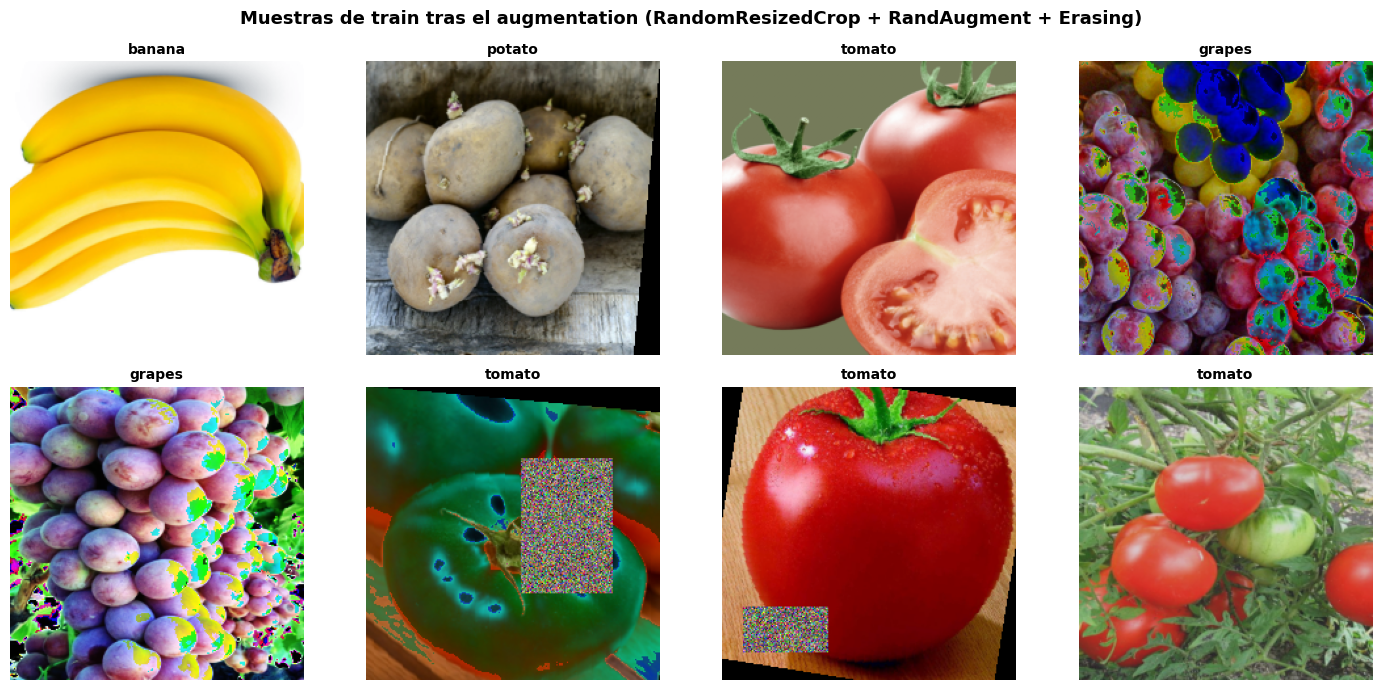

In [ ]:
# ------------------------------------------------------------
# Control visual: ¿qué "ve" realmente el modelo tras el augmentation?
# Si las imágenes quedan irreconocibles para un humano, el augmentation es demasiado agresivo.
# ------------------------------------------------------------
def ver_augmentation(dataset, n=8):
    mean_t = torch.tensor(MEAN).view(3, 1, 1)
    std_t  = torch.tensor(STD).view(3, 1, 1)
    fig, axes = plt.subplots(2, n // 2, figsize=(n * 1.8, 7))
    for ax in axes.flatten():
        idx = random.randrange(len(dataset))
        img, lab = dataset[idx]                       # se re-aplica el augmentation cada vez
        img = (img * std_t + mean_t).clamp(0, 1)      # des-normalizar para poder mostrarla
        ax.imshow(img.permute(1, 2, 0).numpy())
        ax.set_title(CLASES_TL[lab], fontsize=10, fontweight='bold')
        ax.axis('off')
    plt.suptitle('Muestras de train tras el augmentation (RandomResizedCrop + RandAugment + Erasing)',
                 fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()

ver_augmentation(train_ds_tl)


### Paso 3.3 — El modelo: EfficientNet-B0 preentrenado

**¿Por qué EfficientNet-B0 y no ResNet18?**

EfficientNet nace de un *compound scaling*: en vez de agrandar la red solo en profundidad (más capas)
o solo en ancho (más filtros), escala **profundidad, ancho y resolución de forma balanceada**.
Resultado concreto: B0 tiene **5.3M de parámetros** (vs. 11.7M de ResNet18) y aun así obtiene
**mejor top-1 en ImageNet (~77.7% vs ~69.8%)**. Con un dataset de 400 imágenes, menos parámetros =
menos superficie para overfittear. Es el mejor punto de la curva calidad/tamaño para arrancar.

**Cirugía del modelo:** el modelo original termina en `Linear(1280 → 1000)` (las 1000 clases de
ImageNet). Reemplazo ese clasificador por uno nuevo `Dropout → Linear(1280 → 5)`.
El backbone (`model.features`) queda intacto con todo su conocimiento visual.


In [ ]:
# ============================================================
# 3.3 · EfficientNet-B0 con cabeza custom
# ============================================================
def crear_efficientnet_b0(num_classes=5, dropout=0.4, congelar_backbone=True):
    """
    Devuelve un EfficientNet-B0 preentrenado en ImageNet con el clasificador
    reemplazado por uno de `num_classes` salidas.

    congelar_backbone=True  -> Fase A (feature extraction): solo el head entrena.
    congelar_backbone=False -> Fase B (fine-tuning): todo entrena.
    """
    pesos = EfficientNet_B0_Weights.IMAGENET1K_V1        # pesos ImageNet (top-1 ~77.7%)
    modelo = efficientnet_b0(weights=pesos)

    # El clasificador original es: Sequential(Dropout, Linear(1280, 1000))
    n_features = modelo.classifier[1].in_features        # 1280
    modelo.classifier = nn.Sequential(
        nn.Dropout(p=dropout, inplace=True),
        nn.Linear(n_features, num_classes)              # 1280 -> 5 clases
    )

    # Congelo el extractor de features (todo menos el clasificador nuevo)
    if congelar_backbone:
        for param in modelo.features.parameters():
            param.requires_grad = False

    return modelo


def contar_params(modelo):
    entrenables = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    total = sum(p.numel() for p in modelo.parameters())
    return entrenables, total


modelo_tl = crear_efficientnet_b0(NUM_CLASES_TL, DROPOUT_HEAD, congelar_backbone=True).to(device)
ent, tot = contar_params(modelo_tl)
print(f'✅ EfficientNet-B0 cargado con pesos de ImageNet')
print(f'   Parámetros totales     : {tot:,}')
print(f'   Entrenables (Fase A)   : {ent:,}  ({ent/tot:.2%} del total)')
print(f'   Clasificador nuevo     : {modelo_tl.classifier}')

# Sanity check de dimensiones
with torch.no_grad():
    salida = modelo_tl(torch.randn(2, 3, IMG_SIZE_TL, IMG_SIZE_TL).to(device))
print(f'   Test forward: entrada (2,3,{IMG_SIZE_TL},{IMG_SIZE_TL}) -> salida {tuple(salida.shape)} ✔')


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 131MB/s] 


✅ EfficientNet-B0 cargado con pesos de ImageNet
   Parámetros totales     : 4,013,953
   Entrenables (Fase A)   : 6,405  (0.16% del total)
   Clasificador nuevo     : Sequential(
  (0): Dropout(p=0.4, inplace=True)
  (1): Linear(in_features=1280, out_features=5, bias=True)
)
   Test forward: entrada (2,3,224,224) -> salida (2, 5) ✔


### Paso 3.4 — Motor de entrenamiento (con F1 weighted y AMP)

Tres diferencias clave respecto del loop del baseline:

1. **La métrica de selección es F1 Score Weighted**, no `val_loss` ni accuracy.
   Guardo el checkpoint del epoch con **mejor F1 en validación**: optimizo exactamente
   lo que la competencia evalúa.
2. **AMP (Automatic Mixed Precision)**: computa en `float16` donde es seguro. En una T4 esto da
   ~2x de velocidad y menos memoria → puedo usar 224px y batch 32 sin problemas.
3. **Label smoothing (0.1)**: en vez de pedirle al modelo que prediga `[0,0,1,0,0]` (confianza
   absoluta), le pido `[0.02,0.02,0.92,0.02,0.02]`. Reduce la overconfianza y suele mejorar la
   generalización, sobre todo con datasets chicos.


In [ ]:
# ============================================================
# 3.4 · Funciones de entrenamiento y evaluación
# ============================================================
usar_amp = (device.type == 'cuda')
scaler = torch.amp.GradScaler('cuda', enabled=usar_amp)   # escala los gradientes en fp16


def entrenar_epoch_tl(modelo, loader, criterio, optimizador):
    """Un epoch de entrenamiento con mixed precision."""
    modelo.train()
    perdida_total, correctos, total = 0.0, 0, 0

    for imgs, labels in loader:
        imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizador.zero_grad(set_to_none=True)

        with torch.amp.autocast('cuda', enabled=usar_amp):   # forward en fp16
            salidas = modelo(imgs)
            perdida = criterio(salidas, labels)

        scaler.scale(perdida).backward()   # backward sobre la loss escalada (evita underflow en fp16)
        scaler.step(optimizador)
        scaler.update()

        perdida_total += perdida.item() * imgs.size(0)
        correctos += salidas.argmax(1).eq(labels).sum().item()
        total += imgs.size(0)

    return perdida_total / total, correctos / total


@torch.no_grad()
def evaluar_tl(modelo, loader, criterio):
    """Evalúa y devuelve (loss, accuracy, f1_weighted, predicciones, etiquetas_reales)."""
    modelo.eval()
    perdida_total, total = 0.0, 0
    preds_all, labels_all = [], []

    for imgs, labels in loader:
        imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        with torch.amp.autocast('cuda', enabled=usar_amp):
            salidas = modelo(imgs)
            perdida = criterio(salidas, labels)
        perdida_total += perdida.item() * imgs.size(0)
        total += imgs.size(0)
        preds_all.extend(salidas.argmax(1).cpu().numpy())
        labels_all.extend(labels.cpu().numpy())

    preds_all = np.array(preds_all); labels_all = np.array(labels_all)
    acc = (preds_all == labels_all).mean()
    # ⭐ LA MÉTRICA OFICIAL DE LA COMPETENCIA
    f1w = f1_score(labels_all, preds_all, average='weighted', zero_division=0)
    return perdida_total / total, acc, f1w, preds_all, labels_all


def loop_entrenamiento(modelo, epochs, optimizador, scheduler, criterio,
                       historial, fase='', mejor_f1=0.0, ckpt_path=CKPT_TL):
    """
    Bucle principal. Guarda checkpoint en el epoch con MEJOR F1 WEIGHTED de validación
    (no con mejor loss: optimizamos la métrica del leaderboard).
    Devuelve el mejor F1 alcanzado.
    """
    print(f'\n{"="*78}')
    print(f'  {fase}')
    print(f'{"="*78}')
    print(f'{"Ep":>3} | {"Tr Loss":>8} | {"Tr Acc":>7} | {"Va Loss":>8} | {"Va Acc":>7} | {"Va F1-W":>8} | {"LR":>8} |')
    print('-' * 78)

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = entrenar_epoch_tl(modelo, train_loader_tl, criterio, optimizador)
        va_loss, va_acc, va_f1, _, _ = evaluar_tl(modelo, val_loader_tl, criterio)
        if scheduler is not None:
            scheduler.step()

        lr_actual = optimizador.param_groups[-1]['lr']
        for k, v in [('train_loss', tr_loss), ('train_acc', tr_acc),
                     ('val_loss', va_loss), ('val_acc', va_acc), ('val_f1', va_f1)]:
            historial[k].append(v)

        marca = ''
        if va_f1 > mejor_f1:            # criterio de guardado = F1 weighted
            mejor_f1 = va_f1
            torch.save({
                'epoch': int(epoch),
                'fase': str(fase),
                'model_state_dict': modelo.state_dict(),
                'val_f1': float(va_f1),      # ⚠️ float() nativo: f1_score devuelve np.float64
                'val_acc': float(va_acc),    #    y torch.load(weights_only=True) lo rechaza
                'clases': list(CLASES_TL),
            }, ckpt_path)
            marca = ' ⭐'

        print(f'{epoch:>3} | {tr_loss:>8.4f} | {tr_acc:>6.1%} | {va_loss:>8.4f} | '
              f'{va_acc:>6.1%} | {va_f1:>8.4f} | {lr_actual:>8.2e} | {time.time()-t0:>4.0f}s{marca}')

    return mejor_f1


criterio_tl = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTH)
historial_tl = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
print('✅ Motor de entrenamiento listo (AMP:', usar_amp, '| selección por F1-weighted)')


✅ Motor de entrenamiento listo (AMP: True | selección por F1-weighted)


#### Fase A — *Feature Extraction* (backbone congelado)

Solo entrena el clasificador (~6.4k parámetros de 5.3M). El objetivo no es llegar al mejor score,
sino **calibrar el head** para que en la Fase B no mande gradientes destructivos al backbone.
Debería ser muy rápido (segundos por epoch) porque no se calculan gradientes del backbone.


In [ ]:
# ============================================================
# FASE A · Solo el clasificador entrena
# ============================================================
optimizador_A = optim.AdamW(
    [p for p in modelo_tl.parameters() if p.requires_grad],   # solo params del head
    lr=LR_HEAD, weight_decay=WEIGHT_DECAY
)
scheduler_A = optim.lr_scheduler.CosineAnnealingLR(optimizador_A, T_max=EPOCHS_HEAD)

mejor_f1_tl = loop_entrenamiento(
    modelo_tl, EPOCHS_HEAD, optimizador_A, scheduler_A, criterio_tl,
    historial_tl, fase='FASE A · Feature Extraction (backbone CONGELADO)', mejor_f1=0.0
)
epochs_fase_A = len(historial_tl['val_f1'])   # para marcar el corte en los gráficos
print(f'\n✅ Fin Fase A | Mejor F1-weighted en val: {mejor_f1_tl:.4f}')



  FASE A · Feature Extraction (backbone CONGELADO)
 Ep |  Tr Loss |  Tr Acc |  Va Loss |  Va Acc |  Va F1-W |       LR |
------------------------------------------------------------------------------
  1 |   1.4651 |  43.8% |   1.2034 |  80.9% |   0.8041 | 9.33e-04 |   26s ⭐
  2 |   1.1395 |  75.4% |   0.9697 |  91.5% |   0.9125 | 7.50e-04 |   13s ⭐
  3 |   0.9407 |  86.2% |   0.8688 |  95.7% |   0.9571 | 5.00e-04 |   14s ⭐
  4 |   0.8596 |  87.3% |   0.8257 |  95.7% |   0.9571 | 2.50e-04 |   14s
  5 |   0.8256 |  86.9% |   0.8043 |  95.7% |   0.9571 | 6.70e-05 |   13s
  6 |   0.8232 |  88.1% |   0.7968 |  93.6% |   0.9348 | 0.00e+00 |   13s

✅ Fin Fase A | Mejor F1-weighted en val: 0.9571


#### Fase B — *Fine-tuning* completo con LR discriminativos

Ahora descongelo **todo** el backbone. La clave es que **no todas las capas deben aprender igual**:

- Las **capas tempranas** del backbone detectan bordes, colores y texturas: eso es universal, ya está
  perfecto desde ImageNet. → LR muy bajo (`3e-5`).
- El **clasificador** es nuevo y específico de las 5 clases del problema. → LR 10x más alto (`3e-4`).

Esto se implementa con **param groups** en el optimizador. Además uso `CosineAnnealingLR`, que baja
el LR suavemente hasta ~0: el modelo hace exploración al principio y refinamiento fino al final.


In [ ]:
# ============================================================
# FASE B · Fine-tuning completo con learning rates discriminativos
# ============================================================

# 1) Descongelar todo el backbone
for param in modelo_tl.features.parameters():
    param.requires_grad = True

ent, tot = contar_params(modelo_tl)
print(f'🔓 Backbone descongelado | Entrenables ahora: {ent:,} / {tot:,} ({ent/tot:.1%})')

# 2) Param groups: LR distinto para backbone y para el head
optimizador_B = optim.AdamW([
    {'params': modelo_tl.features.parameters(),   'lr': LR_FT_BACKBONE},  # 3e-5  -> conservador
    {'params': modelo_tl.classifier.parameters(), 'lr': LR_FT_HEAD},      # 3e-4  -> agresivo
], weight_decay=WEIGHT_DECAY)

# 3) Cosine annealing: decae el LR de forma suave hasta casi 0 al final del entrenamiento
scheduler_B = optim.lr_scheduler.CosineAnnealingLR(optimizador_B, T_max=EPOCHS_FT, eta_min=1e-7)

mejor_f1_tl = loop_entrenamiento(
    modelo_tl, EPOCHS_FT, optimizador_B, scheduler_B, criterio_tl,
    historial_tl, fase='FASE B · Fine-tuning (backbone DESCONGELADO)', mejor_f1=mejor_f1_tl
)
print(f'\n🏆 Mejor F1-weighted en validación (global): {mejor_f1_tl:.4f}')
print(f'   Checkpoint guardado en: {CKPT_TL}')


🔓 Backbone descongelado | Entrenables ahora: 4,013,953 / 4,013,953 (100.0%)

  FASE B · Fine-tuning (backbone DESCONGELADO)
 Ep |  Tr Loss |  Tr Acc |  Va Loss |  Va Acc |  Va F1-W |       LR |
------------------------------------------------------------------------------
  1 |   0.8267 |  86.9% |   0.7159 |  95.7% |   0.9571 | 2.99e-04 |   29s
  2 |   0.7295 |  91.2% |   0.6757 |  95.7% |   0.9580 | 2.97e-04 |   14s ⭐
  3 |   0.6594 |  93.1% |   0.6403 |  93.6% |   0.9348 | 2.93e-04 |   14s
  4 |   0.6506 |  93.1% |   0.6249 |  93.6% |   0.9348 | 2.87e-04 |   14s
  5 |   0.6191 |  92.3% |   0.6109 |  95.7% |   0.9571 | 2.80e-04 |   14s
  6 |   0.6174 |  92.7% |   0.5982 |  95.7% |   0.9571 | 2.71e-04 |   14s
  7 |   0.5778 |  94.6% |   0.5950 |  95.7% |   0.9571 | 2.61e-04 |   14s
  8 |   0.5616 |  95.0% |   0.5874 |  95.7% |   0.9580 | 2.50e-04 |   14s
  9 |   0.5457 |  95.0% |   0.5849 |  95.7% |   0.9580 | 2.38e-04 |   13s
 10 |   0.5643 |  93.8% |   0.5828 |  95.7% |   0.9571 | 2.

### Paso 3.5 — Evaluación y análisis de errores

Cargo el mejor checkpoint (el de mayor F1 en val) y analizo:

1. **Curvas de entrenamiento** — con la línea vertical que separa Fase A de Fase B.
2. **Classification report** — precision/recall/F1 por clase. Busco clases con recall bajo:
   son las que rompen el F1 weighted.
3. **Matriz de confusión** — qué se confunde con qué (¿apple↔tomato? es la confusión esperable).
4. **Val normal vs. Val HARD** — el termómetro del *domain gap*. La brecha entre ambos estima
   cuánto se apoya el modelo en el fondo blanco.


/tmp/ipykernel_507/484554031.py:31: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


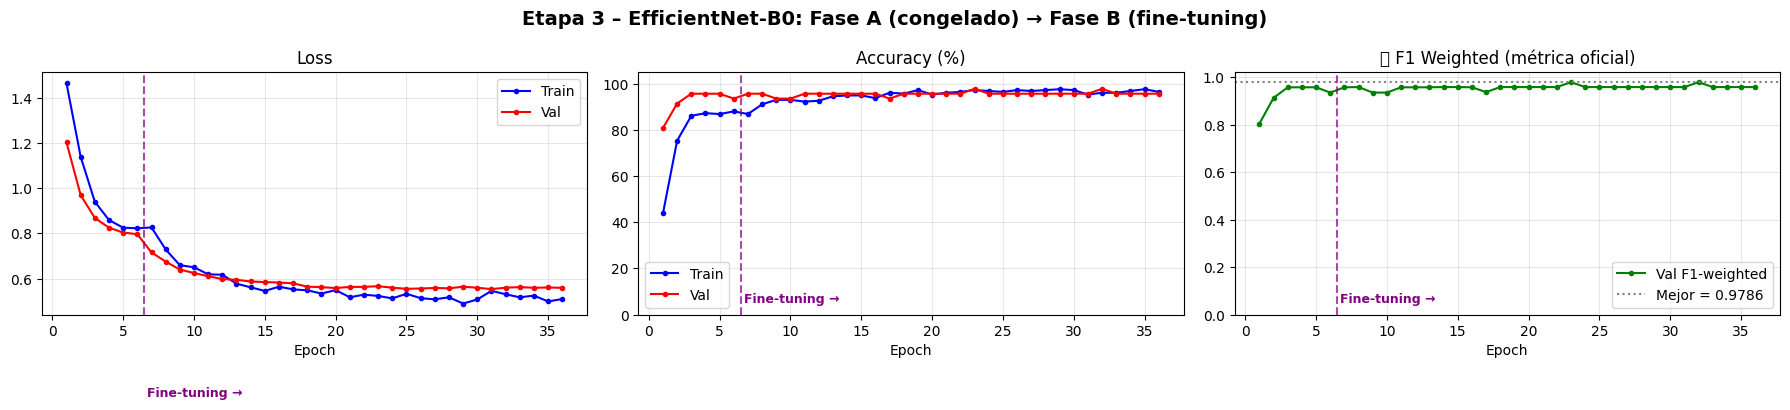

In [ ]:
# ============================================================
# 3.5 · Curvas de entrenamiento
# ============================================================
def graficar_historial_tl(hist, corte_fase):
    ep = range(1, len(hist['train_loss']) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

    axes[0].plot(ep, hist['train_loss'], 'b-o', ms=3, label='Train')
    axes[0].plot(ep, hist['val_loss'], 'r-o', ms=3, label='Val')
    axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(alpha=.3)

    axes[1].plot(ep, [a*100 for a in hist['train_acc']], 'b-o', ms=3, label='Train')
    axes[1].plot(ep, [a*100 for a in hist['val_acc']], 'r-o', ms=3, label='Val')
    axes[1].set_title('Accuracy (%)'); axes[1].set_xlabel('Epoch'); axes[1].set_ylim(0, 105)
    axes[1].legend(); axes[1].grid(alpha=.3)

    axes[2].plot(ep, hist['val_f1'], 'g-o', ms=3, label='Val F1-weighted')
    axes[2].axhline(max(hist['val_f1']), color='gray', ls=':',
                    label=f'Mejor = {max(hist["val_f1"]):.4f}')
    axes[2].set_title('⭐ F1 Weighted (métrica oficial)'); axes[2].set_xlabel('Epoch')
    axes[2].set_ylim(0, 1.02); axes[2].legend(); axes[2].grid(alpha=.3)

    # Línea que separa Fase A (head) de Fase B (fine-tuning)
    for ax in axes:
        ax.axvline(corte_fase + 0.5, color='purple', ls='--', alpha=.7)
        ax.text(corte_fase + 0.7, ax.get_ylim()[1]*0.05, 'Fine-tuning →',
                color='purple', fontsize=9, fontweight='bold')

    plt.suptitle('Etapa 3 – EfficientNet-B0: Fase A (congelado) → Fase B (fine-tuning)',
                 fontsize=14, fontweight='bold')
    plt.tight_layout(); plt.show()

graficar_historial_tl(historial_tl, epochs_fase_A)


✅ Checkpoint cargado | epoch 17 de "FASE B · Fine-tuning (backbone DESCONGELADO)" | val F1=0.9786

────────────────────────────────────────────────────────────
VAL NORMAL  → Accuracy: 97.87% | F1 weighted: 0.9786
────────────────────────────────────────────────────────────
              precision    recall  f1-score   support

       apple      1.000     1.000     1.000         8
      banana      1.000     1.000     1.000         9
      grapes      1.000     1.000     1.000        11
      potato      1.000     0.889     0.941         9
      tomato      0.909     1.000     0.952        10

    accuracy                          0.979        47
   macro avg      0.982     0.978     0.979        47
weighted avg      0.981     0.979     0.979        47

────────────────────────────────────────────────────────────
VAL HARD (proxy del test de Kaggle) → F1 weighted: 0.9293
📉 Domain gap estimado: +0.0493
   Una brecha grande (>0.10) indica que el modelo todavía se apoya en el fondo/encuadre

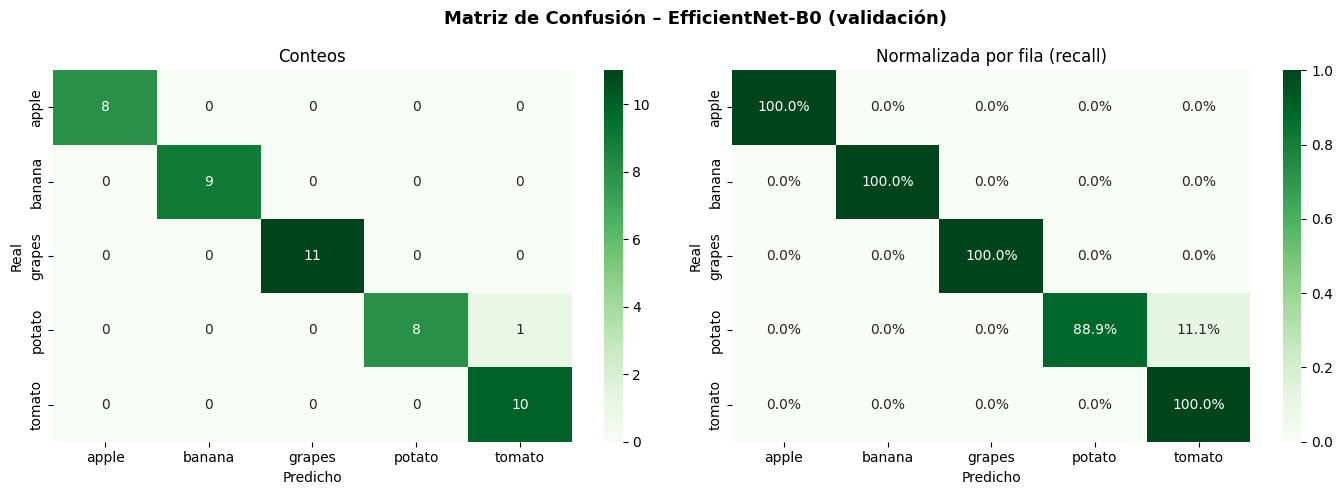

In [ ]:
# ============================================================
# 3.5b · Reporte por clase + matriz de confusión + termómetro del domain gap
# ============================================================
# Cargar el MEJOR checkpoint (mayor F1 en validación)
ckpt = torch.load(CKPT_TL, map_location=device, weights_only=False)
modelo_tl.load_state_dict(ckpt['model_state_dict'])
print(f'✅ Checkpoint cargado | epoch {ckpt["epoch"]} de "{ckpt["fase"]}" | val F1={ckpt["val_f1"]:.4f}\n')

# --- Validación estándar (mismo dominio que train: fondo blanco) ---
vl, va, vf1, preds_va, labels_va = evaluar_tl(modelo_tl, val_loader_tl, criterio_tl)
print('─' * 60)
print(f'VAL NORMAL  → Accuracy: {va:.2%} | F1 weighted: {vf1:.4f}')
print('─' * 60)
print(classification_report(labels_va, preds_va, target_names=CLASES_TL,
                            digits=3, zero_division=0))

# --- Validación "HARD": crops + color jitter fuertes = proxy del test con fondos variados ---
# Promedio 3 pasadas porque las transforms son aleatorias.
f1_hard = np.mean([evaluar_tl(modelo_tl, val_hard_loader_tl, criterio_tl)[2] for _ in range(3)])
print('─' * 60)
print(f'VAL HARD (proxy del test de Kaggle) → F1 weighted: {f1_hard:.4f}')
print(f'📉 Domain gap estimado: {vf1 - f1_hard:+.4f}')
print('   Una brecha grande (>0.10) indica que el modelo todavía se apoya en el fondo/encuadre.')
print('   Esperá que tu score de Kaggle esté MÁS CERCA del val_hard que del val normal.')
print('─' * 60)

# --- Matriz de confusión ---
cm = confusion_matrix(labels_va, preds_va)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=CLASES_TL, yticklabels=CLASES_TL, ax=ax1)
sns.heatmap(cm_norm, annot=True, fmt='.1%', cmap='Greens',
            xticklabels=CLASES_TL, yticklabels=CLASES_TL, ax=ax2)
ax1.set_title('Conteos'); ax2.set_title('Normalizada por fila (recall)')
for ax in (ax1, ax2):
    ax.set_ylabel('Real'); ax.set_xlabel('Predicho')
plt.suptitle('Matriz de Confusión – EfficientNet-B0 (validación)', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()


In [ ]:
# ============================================================
# 3.6 · Comparación directa: Baseline (CNN scratch) vs. EfficientNet-B0
# ============================================================
comparacion = pd.DataFrame([
    {'Modelo': 'CNN desde cero (Etapa 2)', 'Resolución': '64x64',
     'Params entrenables': '2,192,389',
     'Mejor Val Acc': f'{max(historial_r["val_acc"]):.2%}',
     'Mejor Val F1-W': '— (no se medía)'},
    {'Modelo': 'EfficientNet-B0 (Etapa 3)', 'Resolución': '224x224',
     'Params entrenables': f'{contar_params(modelo_tl)[0]:,}',
     'Mejor Val Acc': f'{max(historial_tl["val_acc"]):.2%}',
     'Mejor Val F1-W': f'{max(historial_tl["val_f1"]):.4f}'},
])
print(comparacion.to_string(index=False))


                   Modelo Resolución Params entrenables Mejor Val Acc  Mejor Val F1-W
 CNN desde cero (Etapa 2)      64x64          2,192,389        76.09% — (no se medía)
EfficientNet-B0 (Etapa 3)    224x224          4,013,953        97.87%          0.9786


### Paso 3.7 — Predicción con TTA y generación del `submission.csv`

**Test-Time Augmentation (TTA):** en vez de predecir una sola vez sobre cada imagen de test,
predigo sobre **varias versiones** de la misma (original, espejada horizontal, espejada vertical)
y **promedio las probabilidades**. Es un mini-ensemble gratis: no requiere entrenar nada más y
típicamente suma entre +0.5 y +2 puntos de F1, porque cancela errores que dependen de la orientación.

⚠️ **Detalle crítico del formato:** el notebook de la Etapa 2 guardaba `image_id` **sin extensión**
(`img_00000`). Acá leo el `sample_submission.csv` de la competencia y **replico exactamente su
formato y su orden de filas**. Un mismatch de formato = score 0 aunque el modelo sea perfecto.


In [ ]:
# ============================================================
# 3.7 · Inferencia con TTA + submission
# ============================================================

@torch.no_grad()
def predecir_con_tta(modelo, rutas, transform, usar_tta=True, batch=32):
    """
    Devuelve la matriz de probabilidades (N, 5) promediando sobre variantes TTA.
    TTA = original + flip horizontal + flip vertical (promedio de softmax).
    """
    modelo.eval()
    probas_acumuladas = []

    for i in range(0, len(rutas), batch):
        lote = rutas[i:i + batch]
        tensores = torch.stack([transform(cargar_rgb(p, fondo_aleatorio=False)) for p in lote]).to(device)

        # Variantes de test-time augmentation
        variantes = [tensores]
        if usar_tta:
            variantes.append(torch.flip(tensores, dims=[3]))   # espejo horizontal
            variantes.append(torch.flip(tensores, dims=[2]))   # espejo vertical

        acum = torch.zeros(len(lote), NUM_CLASES_TL, device=device)
        for v in variantes:
            with torch.amp.autocast('cuda', enabled=usar_amp):
                logits = modelo(v)
            acum += torch.softmax(logits.float(), dim=1)       # promedio PROBABILIDADES, no logits
        acum /= len(variantes)
        probas_acumuladas.append(acum.cpu().numpy())

    return np.concatenate(probas_acumuladas, axis=0)


# --- 1) Imágenes de test (ya descargadas en la celda de la Etapa 2) ---
DIR_TEST = Path('/content/data/test_competencia')
imagenes_test = sorted([p for p in DIR_TEST.rglob('*')
                        if p.suffix.lower() in {'.jpg', '.jpeg', '.png'}])
print(f'🖼️  {len(imagenes_test)} imágenes de test encontradas')

# --- 2) Detectar el formato EXACTO de image_id que espera Kaggle ---
sample_paths = list(DIR_TEST.rglob('sample_submission.csv'))
if sample_paths:
    df_sample = pd.read_csv(sample_paths[0])
    ids_sample = df_sample['image_id'].astype(str)
    usa_extension = ids_sample.str.contains(r'\.\w+$', regex=True).any()
    print(f'📋 sample_submission.csv encontrado | ejemplo de image_id: "{ids_sample.iloc[0]}"')
    print(f'   → ¿lleva extensión?: {usa_extension}')
else:
    df_sample, usa_extension = None, False
    print('⚠️  No se encontró sample_submission.csv; se asume image_id SIN extensión.')

# --- 3) Predecir con TTA ---
probas = predecir_con_tta(modelo_tl, imagenes_test, transform_eval_tl, usar_tta=True)
indices_pred = probas.argmax(axis=1)
confianzas   = probas.max(axis=1)

df_sub_tl = pd.DataFrame({
    'image_id': [p.name if usa_extension else p.stem for p in imagenes_test],
    'label':    [CLASES_TL[i] for i in indices_pred],
})

# --- 4) Alinear con el orden exacto del sample_submission (si existe) ---
if df_sample is not None:
    df_sub_tl = (df_sample[['image_id']]
                 .merge(df_sub_tl, on='image_id', how='left'))
    faltantes = df_sub_tl['label'].isna().sum()
    if faltantes:
        print(f'⚠️  {faltantes} filas sin predicción (mismatch de image_id). Reviso el formato...')
        df_sub_tl['label'] = df_sub_tl['label'].fillna('apple')   # fallback defensivo
    else:
        print('✅ Todos los image_id del sample fueron predichos correctamente')

# --- 5) Validaciones + guardado ---
assert df_sub_tl['label'].isin(CLASES_TL).all(), '❌ Hay labels fuera de las 5 clases válidas'
assert list(df_sub_tl.columns) == ['image_id', 'label'], '❌ Columnas incorrectas'

df_sub_tl.to_csv('/content/submission_efficientnet.csv', index=False)

print('\n📊 Distribución de predicciones:')
print(df_sub_tl['label'].value_counts().to_string())
print(f'\n🎯 Confianza media del modelo: {confianzas.mean():.2%} '
      f'| imágenes con confianza < 60%: {(confianzas < 0.6).sum()}')
print('\n📄 Guardado: /content/submission_efficientnet.csv')
print('   → Subilo en https://www.kaggle.com/competitions/utn-ia-2026-fruit-vegetable-classifier/submit')
print(df_sub_tl.head(10).to_string(index=False))


🖼️  89 imágenes de test encontradas
📋 sample_submission.csv encontrado | ejemplo de image_id: "img_00000"
   → ¿lleva extensión?: False
✅ Todos los image_id del sample fueron predichos correctamente

📊 Distribución de predicciones:
label
grapes    22
tomato    20
apple     16
banana    16
potato    15

🎯 Confianza media del modelo: 79.58% | imágenes con confianza < 60%: 12

📄 Guardado: /content/submission_efficientnet.csv
   → Subilo en https://www.kaggle.com/competitions/utn-ia-2026-fruit-vegetable-classifier/submit
 image_id  label
img_00000 grapes
img_00001 grapes
img_00002  apple
img_00003 banana
img_00004 tomato
img_00005 grapes
img_00006 potato
img_00007 potato
img_00008 grapes
img_00009 potato


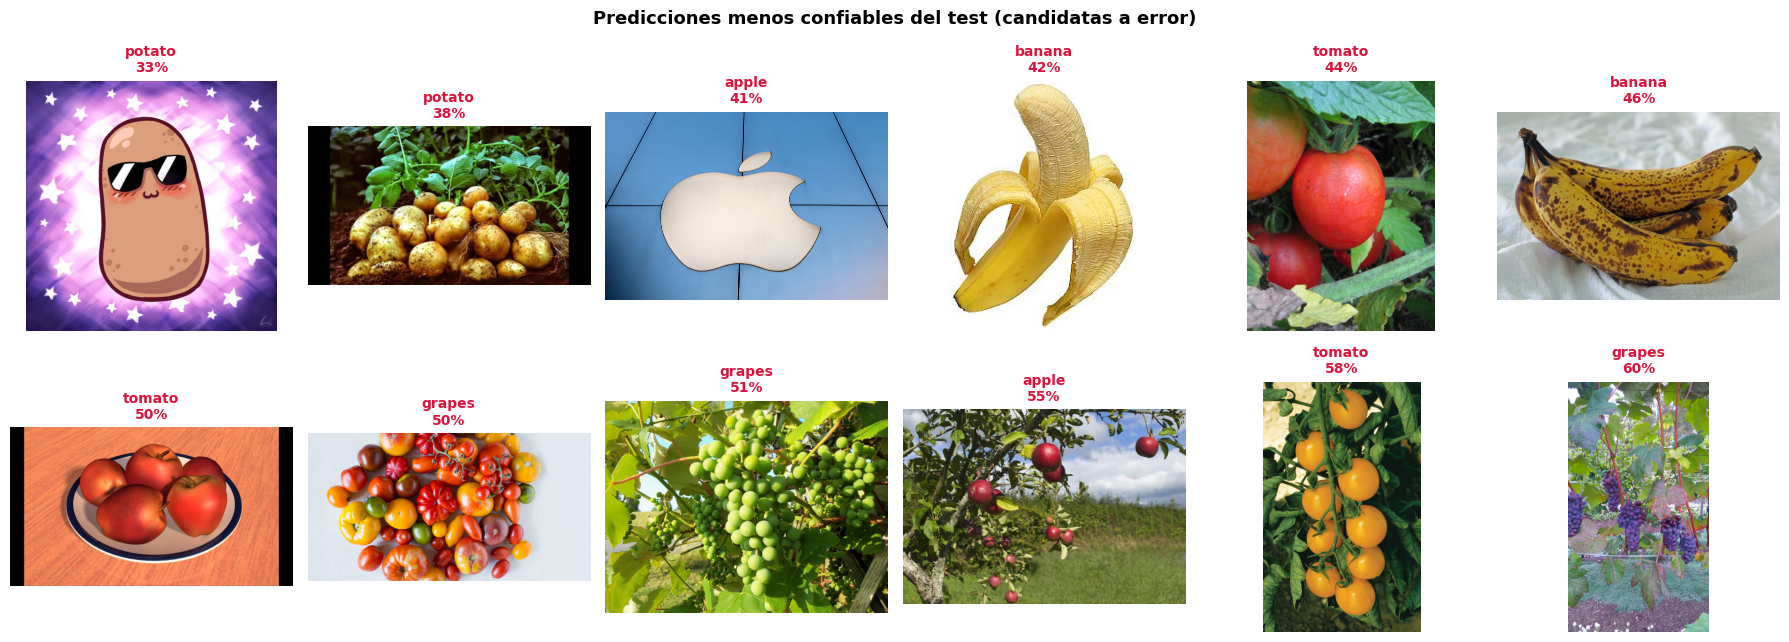

In [ ]:
# ------------------------------------------------------------
# Auditoría cualitativa: las 12 predicciones MENOS confiables.
# Estas imágenes son oro puro: te dicen exactamente dónde falla el modelo
# y qué augmentation / clase necesita refuerzo en el próximo experimento.
# ------------------------------------------------------------
orden = np.argsort(confianzas)[:12]
fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
for ax, idx in zip(axes.flatten(), orden):
    ax.imshow(cargar_rgb(imagenes_test[idx]))
    ax.set_title(f'{CLASES_TL[indices_pred[idx]]}\n{confianzas[idx]:.0%}',
                 fontsize=10, color='crimson', fontweight='bold')
    ax.axis('off')
plt.suptitle('Predicciones menos confiables del test (candidatas a error)',
             fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()


# Bitácora de Experimentos — UTN-IA 2026 · Fruit & Vegetable Classifier

Documento vivo. Cada experimento se registra con **hipótesis → cambio → resultado → conclusión**.
La única métrica que decide es **F1 Score Weighted** en el leaderboard de Kaggle.

---

## Experimento #0 — Baseline (notebook de clase)

**Modelo:** CNN desde cero (3 bloques Conv-BN-ReLU-MaxPool + MLP), 2.19M parámetros, 64×64 px.

| Métrica | Valor |
|---|---|
| Val Accuracy (Etapa 1, estudio visual) | 100 % |
| Val Accuracy (Etapa 2, dataset oficial) | **76.1 %** (epoch 15 de 20) |
| F1 Weighted en Kaggle | ≤ 0.634 (cota máxima, ver nota) |

> **Nota sobre el F1 del baseline.** Como el Experimento #1 obtuvo F1 = 1.0 en Kaggle, sus predicciones
> coinciden con las etiquetas reales del test: grapes 22, tomato 20, apple 16, banana 16, potato 15.
> El baseline predijo grapes 38, tomato 28, banana 18, potato 3, apple 2. Aun suponiendo que acertó todo
> lo posible dentro de cada clase, su F1 weighted no puede superar 0.634.


### Diagnóstico: por qué el baseline no alcanza

Al ejecutar el notebook original quedaron cuatro patologías visibles:

1. **Datos insuficientes para entrenar desde cero.** El dataset oficial tiene ~420 imágenes
   (325 train / 46 val / 46 test). Una CNN de 2.2M de parámetros entrenada sobre 325 imágenes
   está condenada: no hay señal suficiente para aprender features visuales desde ruido aleatorio.
   El train accuracy nunca llegó al 50 % (máximo 49.5 %) — el modelo ni siquiera logró *memorizar* el train.

2. **Resolución 64×64.** A ese tamaño desaparece la textura. La diferencia entre la piel rugosa de
   una papa y la piel lisa de un tomate vive en los detalles de alta frecuencia; a 64 px sólo
   quedan color y silueta. No sorprende que el modelo predijera `grapes` para 38 de las 89
   imágenes de test (son 22): colapsó a la clase más frecuente del train.

3. **Domain gap train↔test.** El train tiene fondo blanco de estudio; el test de Kaggle tiene
   fondos reales y variados. El modelo aprende el atajo *"fondo blanco uniforme + mancha roja =
   tomate"*, y ese atajo **no existe** en el test. Peor: la función `cargar_imagen_limpia` del
   baseline pegaba las imágenes con transparencia **siempre sobre blanco**, reforzando el sesgo.

4. **Métrica de selección incorrecta.** El checkpoint se guardaba por menor `val_loss`. La
   competencia evalúa **F1 weighted**. No son lo mismo: un modelo puede bajar la loss volviéndose
   más confiado en las clases que ya acierta, sin mejorar el F1 en las clases que falla.

---

## Experimento #1 — Transfer Learning con EfficientNet-B0 ✅ implementado

**Hipótesis:** el cuello de botella no es la arquitectura sino la **falta de datos**. Un backbone
preentrenado en ImageNet (1.28M de imágenes, que además incluye clases de frutas) ya trae las
features visuales resueltas; sólo hay que adaptar la última capa. Sumado a atacar el domain gap
con augmentation, el salto debería ser grande.

### Cambios implementados

| # | Cambio | Justificación técnica |
|---|--------|----------------------|
| 1 | **EfficientNet-B0 preentrenado** (`IMAGENET1K_V1`) en lugar de CNN desde cero | 5.3M params y **77.7 % top-1 en ImageNet** (vs. 69.8 % de ResNet18 con 11.7M params). El *compound scaling* escala profundidad, ancho y resolución de forma balanceada → mejor relación calidad/tamaño. Menos parámetros = menos superficie de overfitting con 420 imágenes. |
| 2 | Clasificador reemplazado: `Linear(1280→1000)` → `Dropout(0.4) + Linear(1280→5)` | El backbone conserva todo su conocimiento visual; sólo cambio la "cabeza" de decisión. |
| 3 | **Resolución 224×224** | Resolución nativa del preentrenamiento de B0. Recupera la información de textura que 64×64 destruía. |
| 4 | **Entrenamiento en 2 fases** | *Fase A (6 ep)*: backbone congelado, sólo entrena el head → calibra el clasificador. *Fase B (30 ep)*: backbone descongelado. Si se descongela desde el epoch 1, los gradientes enormes del head random se propagan hacia atrás y **destruyen** los pesos de ImageNet. |
| 5 | **Learning rates discriminativos** (backbone `3e-5`, head `3e-4`) vía *param groups* | Las capas tempranas detectan bordes/colores: eso es universal y ya está óptimo. El head es nuevo y necesita aprender rápido. LR uniforme trata ambas cosas igual, y está mal. |
| 6 | **`CosineAnnealingLR`** | Decae el LR suavemente hasta ~0: exploración al principio, refinamiento fino al final. Más estable que `ReduceLROnPlateau` cuando el número de epochs es fijo. |
| 7 | **Augmentation anti-domain-gap**: `RandomResizedCrop(scale=0.4–1.0)` + flips + `RandAugment(2,9)` + `RandomErasing(0.25)` | `RandomResizedCrop` es la defensa nº1: al recortar entre el 40 % y el 100 % del área, obliga al modelo a reconocer la fruta por **fragmentos y textura**, no por la composición global (donde vive el fondo). `RandAugment` cubre mucha más variabilidad que un `ColorJitter` manual. `RandomErasing` simula oclusiones. |
| 8 | **Fondo aleatorio** para imágenes con canal alpha (en train) | El baseline las pegaba siempre sobre blanco, **reforzando** el sesgo que quiero romper. Ahora en entrenamiento se componen sobre un color aleatorio → se rompe la correlación fondo↔clase. Gratis. |
| 9 | **Label smoothing 0.1** | En vez de exigir confianza absoluta (`[0,0,1,0,0]`), el target es `[0.02,…,0.92,…]`. Reduce la overconfianza y mejora la generalización con datasets chicos. |
| 10 | **Selección de checkpoint por F1 weighted** (no por `val_loss`) | Optimizo exactamente lo que el leaderboard evalúa. |
| 11 | **AMP (mixed precision)** | ~2× de velocidad en la T4 y menos memoria → 224 px con batch 32 sin problemas. |
| 12 | **Dataset reconstruido: deduplicado por hash MD5 + split estratificado** | El código de la Etapa 2 copiaba imágenes desde dos rutas distintas → riesgo real de que la **misma imagen** quedara en train *y* en val (*data leakage* → validación mentirosamente alta). El hash MD5 lo elimina. `stratify=y` garantiza que cada clase mantenga su proporción. |
| 13 | **TTA ×3 en inferencia** (original + flip-H + flip-V, promedio de softmax) | Mini-ensemble gratuito: cancela errores dependientes de la orientación. Típicamente +0.5 a +2 puntos de F1 sin entrenar nada extra. |
| 14 | **`image_id` alineado con `sample_submission.csv`** | El baseline guardaba `img_00000` (sin extensión) por hardcodeo. Ahora se lee el sample de la competencia y se replica su formato y orden exactos. Un mismatch = score 0 aunque el modelo sea perfecto. |
| 15 | **Set de validación "HARD"** (crops + color jitter fuertes) | La val local sale del mismo dominio de fondo blanco que el train → **va a dar ~99 % y es mentira**. El `val_hard` estima cuánto se apoya el modelo en el fondo. La brecha `val_normal − val_hard` es el termómetro del domain gap. |

---

### Resultados

| Métrica | Valor |
|---|---|
| Val F1-Weighted (normal) | 0.9786 |
| Val F1-Weighted (HARD) | 0.9293 |
| Domain gap (normal − hard) | +0.0493 |
| **F1-Weighted en Kaggle** | 1.00000 |

### Conclusión

La hipótesis se confirma: el cuello de botella eran los datos, no la arquitectura. Con el mismo
dataset, pasar a un backbone preentrenado y atacar el domain gap llevó el F1 weighted en Kaggle de
**como máximo 0.634 a 1.0**: las 89 imágenes del test quedaron bien clasificadas.

El `val_hard` (0.929) anticipaba un domain gap moderado, y el resultado en Kaggle quedó incluso por
encima del val normal: las contramedidas contra el fondo (`RandomResizedCrop`, fondo aleatorio,
`RandAugment`) cumplieron su función. Como el test tiene solo 89 imágenes, el 1.0 no garantiza el
mismo desempeño sobre un conjunto más grande; el próximo paso es medir la robustez, no subir el puntaje.
